# Uber Pickups NYC — hot-zones par clustering et prévision de la demande

Copyright © 2026 · voir le fichier LICENSE du dépôt

**Certification CDSD (RNCP35288) — Bloc 3 : analyse prédictive de données structurées par l'intelligence artificielle**
Projet : recommander aux chauffeurs Uber les zones de forte demande à New York selon le jour et l'heure.

Deux volets complémentaires :

1. **où** se trouve la demande : clustering non supervisé (`MiniBatchKMeans`) en hot-zones, par jour de la semaine et pour un créneau (sections 5 à 10) ;
2. **combien** de courses attendre par zone et par heure : prévision supervisée (`Ridge`, `HistGradientBoostingRegressor`), validée dans le temps et comparée à la règle « comme la semaine précédente » (section 10 bis).

Ce notebook couvre : ingestion, nettoyage, feature engineering temporel, projection géographique locale, EDA, choix de l'algorithme et du nombre de clusters, évaluation, cartes des hot-zones, prévision supervisée et limites de mise en production.

---

## Documentation vivante de ce notebook

Cinq rubriques, relues à chaque modification du code : elles disent ce qui a été décidé, où cela vit, comment cela marche et ce qui le prouve.

## CHOIX

- Retenu : un notebook explicatif (le raisonnement reste dans les cellules Markdown) adossé à un module `uber_bloc3.py`, placé à côté de lui, qui contient les fonctions de calcul. Ces fonctions sont testées sans exécuter le notebook ni lire les 100 Mo de données (`tests/test_uber_bloc3.py:379`), et un test d'intégration exécute le notebook sur les données réelles et vérifie ses chiffres clés (`tests/test_notebook_uber.py:107`).
- Retenu : ce que le jury peut vouloir modifier en direct reste dans les cellules, pas dans le module : `RANDOM_STATE` (cellule 2), `SEUIL_NOM_KM` et les réglages de MiniBatchKMeans `TAILLE_APPRENTISSAGE`, `TAILLE_QUALITE`, `BATCH_SIZE`, `N_INIT` et `MAX_ITER` (cellule 12), `K_DAY` (cellule 16), la liste des variables (cellules 28 et 29).
- Retenu pour les hot-zones : `MiniBatchKMeans` sur les coordonnées projetées en kilomètres (adapté à plusieurs millions de points), un modèle par jour de la semaine, et un zonage commun avril à août pour la prévision.
- Retenu pour la prévision : `Ridge` et `HistGradientBoostingRegressor`, validation croisée chronologique (`TimeSeriesSplit`), test sur septembre jamais vu, comparaison à la règle en place « comme la semaine précédente ».
- Écartés, avec la raison : DBSCAN (sensible au rayon `eps`, mesuré en section 9 ter), HDBSCAN (dépendance supplémentaire), un découpage aléatoire de la prévision (il mélangerait passé et futur), un `StandardScaler` sur les coordonnées (il déformerait la carte).
- Écarté pour la conformité : garder les fonctions dans les cellules sans test.

## OÙ

- Rôle : livrable du bloc 3 CDSD (RNCP35288) sur les courses Uber de New York en 2014. Il n'a pas d'appelant : c'est un document final, relu et exécuté de haut en bas.
- Il appelle `uber_bloc3.py` (fonctions de calcul) et lit les six fichiers mensuels de 2014 directement dans l'archive `uber-trip-data.zip` (variable d'environnement `UBER_DATA_ZIP`, dossier extrait ou archive à côté du notebook : voir `LIRE_DONNEES.md`). Il écrit dix fichiers d'agrégats dans `uber_outputs/` (par exemple `uber_outputs/summary.json:2`) ; aucune coordonnée individuelle n'y figure.
- Dépendances : numpy, pandas, scikit-learn, matplotlib et IPython, aux versions épinglées dans `requirements.txt` (celles que la cellule 2 affiche). Les outils de test sont dans `requirements-dev.txt`.

## COMMENT

- Les sections se lisent dans l'ordre : source et empreintes des données (1 et 2), nettoyage (3), exploration (4 et 5), choix de l'algorithme et de k (6 et 7), hot-zones par jour et cartes (8 et 8 bis), vendredi 18 h (9), sensibilité de DBSCAN (9 ter), recommandation (10), prévision supervisée (10 bis), limites (11), RGPD (11 bis), conclusion (12).
- Reproductibilité : `RANDOM_STATE = 42` fixe tous les tirages ; la cellule 4 recalcule l'empreinte SHA-256 des six fichiers et affiche « Empreintes SHA-256 conformes : 6 sur 6 ».
- Tests : `python -m pytest tests -W error::DeprecationWarning -W error::PendingDeprecationWarning`. Les tests du module sont rapides. Les tests du notebook (`-m notebook`) exigent les données : définir `UBER_DATA_ZIP` (sinon ils sont ignorés et le disent). Le notebook entier prend environ une minute. Un test relance aussi les cellules 0 à 30 sans la variable `retard_168h` (`tests/test_notebook_uber.py:149`).

## POURQUOI

- Données : fichiers publics de FiveThirtyEight, https://github.com/fivethirtyeight/uber-tlc-foil-response ; octet pour octet identiques (taille et empreinte Git), voir `LIRE_DONNEES.md`. Référentiel : RNCP35288, bloc 3, https://www.francecompetences.fr/recherche/rncp/35288/
- Les chiffres cités dans le texte sont calculés par le notebook et écrits dans `uber_outputs/summary.json:2` ; aucun n'est saisi à la main.
- Poids du retard d'une semaine (`retard_168h`) : sans cette variable, le modèle ne bat plus la règle en place sur septembre ; le test `tests/test_notebook_uber.py:149` relance les cellules 0 à 30 sans elle et vérifie ce verdict.
- La projection locale en kilomètres (111,320 km par degré de longitude à l'équateur, 110,574 km par degré de latitude) et le seuil de 3 km pour signaler un nom de zone approximatif sont des choix du notebook : source : inconnue.

## JOURNALISATION

- Le notebook ne journalise pas dans un fichier : ses affichages font le journal. Cellule 2 : versions des bibliothèques, source des données retenue. Cellule 4 : lignes, valeurs manquantes et empreinte de chaque fichier (« conforme » ou non), période couverte. Cellule 6 : lignes exclues du nettoyage, avec des exemples. Cellules 16 et 20 : qualité de chaque modèle de zones. Cellule 34 : fichiers d'agrégats écrits.
- Les données sont des géolocalisations horodatées : une donnée personnelle potentielle (section 11 bis). Seuls des agrégats sont exportés ; les cartes ne montrent que des échantillons de points.
- Le module `uber_bloc3.py` ne journalise rien ; ses fonctions sont pures.


## 1. Hypothèses et périmètre

- Les fichiers 2014 (`uber-raw-data-*-14.csv`) contiennent les coordonnées exactes `Lat` / `Lon`. Ce sont donc les données utilisées pour construire les hot-zones.
- Le fichier 2015 contient des `locationID` de zones taxi, mais pas de coordonnées GPS. Il n'est pas utilisé ici, faute de fichier de géométrie des zones.
- Une hot-zone est définie comme un centroïde de cluster ; sa taille est le volume de pickups historiques qu'elle regroupe.
- **Le clustering décrit où la demande se concentre dans l'historique ; il ne prédit pas, à lui seul, la demande future.** La prévision supervisée de la demande par zone et par heure est traitée à part, en section 10 bis, avec une validation dans le temps et une comparaison à la règle en place. Pour une version production, on ajouterait météo, événements, trafic et disponibilité des chauffeurs, puis un test A/B.

In [1]:
# =============================================================================
# 1. Imports, configuration, chemins et source des données
# =============================================================================
# Tous les imports sont regroupés ici, en tête du notebook (convention PEP 8 :
# bibliothèque standard, puis bibliothèques tierces).

# --- Bibliothèque standard ---------------------------------------------------
import io
import json
import math
import os
import platform
import sys
from functools import partial
from pathlib import Path

# Limiter les threads évite certains blocages OpenMP/BLAS sur les environnements notebook.
# Réglage posé AVANT le chargement de NumPy ; il ne change pas les résultats.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

# Le module uber_bloc3.py (les fonctions de calcul, testées dans tests/) est à côté de ce
# notebook. Le noyau Jupyter ne démarre pas toujours dans ce dossier : on l'ajoute au chemin
# d'import AVANT de l'importer, en remontant depuis le dossier courant (comme trouver_racine).
sys.path.insert(
    0,
    str(
        next(
            (
                dossier
                for parent in (Path.cwd(), *Path.cwd().parents)
                for dossier in (parent, parent / "3_Uber")
                if (dossier / "uber_bloc3.py").exists()
            ),
            Path.cwd(),
        )
    ),
)

# --- Bibliothèques tierces ---------------------------------------------------
# Les commentaires « type: ignore » disent à mypy que pandas et scikit-learn ne publient pas
# de types : ils ne changent rien à l'exécution.
import IPython
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # type: ignore[import-untyped]
import sklearn  # type: ignore[import-untyped]
from sklearn.cluster import DBSCAN, MiniBatchKMeans  # type: ignore[import-untyped]
from sklearn.compose import ColumnTransformer  # type: ignore[import-untyped]
from sklearn.ensemble import HistGradientBoostingRegressor  # type: ignore[import-untyped]
from sklearn.inspection import permutation_importance  # type: ignore[import-untyped]
from sklearn.linear_model import Ridge  # type: ignore[import-untyped]
from sklearn.metrics import (  # type: ignore[import-untyped]
    calinski_harabasz_score,
    davies_bouldin_score,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import TimeSeriesSplit, cross_validate  # type: ignore[import-untyped]
from sklearn.pipeline import Pipeline  # type: ignore[import-untyped]
from sklearn.preprocessing import (  # type: ignore[import-untyped]
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

# --- Fonctions de calcul du projet (module testé, à côté du notebook) -------------
from uber_bloc3 import (
    KM_PAR_DEGRE_LATITUDE,
    KM_PAR_DEGRE_LONGITUDE_EQUATEUR,
    GeometrieCarte,
    afficher,
    afficher_markdown,
    choisir_source,
    empreinte_conforme,
    evaluer,
    fit_hotzones,
    from_xy,
    indicateurs,
    lire_octets,
    nearest_zone_name,
    placer_etiquette,
    projeter_en_km,
    qualifier_gain,
    recommend_hotzones_from_history,
    to_xy,
    trouver_racine,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Polices un peu plus grandes que les valeurs par défaut de Matplotlib : les figures restent
# lisibles quand elles sont reprises, réduites, dans le support de présentation.
plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
    }
)

print("Python        :", platform.python_version())
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("scikit-learn  :", sklearn.__version__)
print("matplotlib    :", matplotlib.__version__)
print("IPython       :", IPython.__version__)

# --- Dossier du projet -------------------------------------------------------
# Le noyau Jupyter ne démarre pas toujours dans le dossier du notebook (selon
# l'éditeur, le dossier de travail peut être le dossier parent, ou ailleurs). On cherche
# donc le dossier qui CONTIENT ce notebook, en remontant depuis le dossier courant ;
# à défaut, on garde le dossier courant.
NOM_NOTEBOOK = "Uber_Pickups_Bloc3_CDSD_v2.ipynb"
PROJECT_ROOT = trouver_racine(NOM_NOTEBOOK, "3_Uber")
OUT = PROJECT_ROOT / "uber_outputs"
OUT.mkdir(exist_ok=True)

# --- Source des données ------------------------------------------------------
# Trois sources possibles, par ordre de priorité (voir LIRE_DONNEES.md) :
# 1. la variable d'environnement UBER_DATA_ZIP, qui désigne l'archive « uber-trip-data.zip »
#    où qu'elle se trouve (par exemple sur un autre disque) ;
# 2. un dossier « uber-trip-data/ » déjà extrait, à côté du notebook ;
# 3. l'archive « uber-trip-data.zip » à côté du notebook.
# Les fichiers sont lus DIRECTEMENT dans l'archive : rien n'est extrait ni écrit sur le disque.
# choisir_source (uber_bloc3.py, testée) applique cet ordre et lève FileNotFoundError si
# aucune source n'existe.
SOURCE, DATA_ZIP, DATA_DIR = choisir_source(os.environ.get("UBER_DATA_ZIP"), PROJECT_ROOT)

print("Dossier du projet :", PROJECT_ROOT.name)
print("Source des données :", SOURCE, "→", (DATA_ZIP if SOURCE == "archive" else DATA_DIR).name)

Python        : 3.12.14
numpy         : 2.5.4
pandas        : 3.0.6
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
IPython       : 9.17.1
Dossier du projet : 3_Uber
Source des données : archive → uber-trip-data.zip


## 2. Ingestion des données 2014 et contrôle du schéma

Les fichiers mensuels 2014 ont le schéma minimal attendu pour le clustering géographique : horodatage, latitude, longitude, base Uber. Chaque fichier est lu depuis sa source et son **empreinte SHA-256** est comparée à celle des fichiers publics d'origine (FiveThirtyEight, voir `LIRE_DONNEES.md`) : on s'assure ainsi que l'analyse porte sur les données publiées.

In [2]:
# Empreintes SHA-256 attendues des six fichiers mensuels (voir LIRE_DONNEES.md).
SHA256_ATTENDUS = {
    "apr": "4c92b95b9918e73ae84bade0bffef6e758e792c247469523130d3c1ad7b646e0",
    "may": "3940ebee250998e32e810fed596fa2e5ac170e6926e0da43b977b6f76c6921e9",
    "jun": "ca999fb126a068a429c266d6781b1e8825b2acc1c74644481222ca6f01dbb557",
    "jul": "42bc47c906a3d17b2b4f9543594ab300db9ac5f8bbb7a6060d215fa30a8c62c2",
    "aug": "710e5766a8f2c13cfa9fd1dda30a4f6c5cba1b964a1efeb7087df0085a86f091",
    "sep": "3c7bda88de4106b5ebeb489545a17b09133a6e5c0efde71d9666d0ee14b7b7d9",
}
MOIS = {"apr": 4, "may": 5, "jun": 6, "jul": 7, "aug": 8, "sep": 9}


# lire_octets(mois, source, data_dir, data_zip) est dans uber_bloc3.py (testée) : contenu brut
# du fichier d'un mois, depuis l'archive ou le dossier extrait. Dans l'archive, les entrées
# « __MACOSX » (métadonnées ajoutées par certains outils de compression) sont écartées.
# empreinte_conforme(octets, attendue) compare l'empreinte SHA-256 à celle de LIRE_DONNEES.md.

frames = []
file_stats = []
for mois, numero_mois in MOIS.items():
    octets = lire_octets(mois, SOURCE, DATA_DIR, DATA_ZIP)
    tmp = pd.read_csv(io.BytesIO(octets))
    nom_fichier = f"uber-raw-data-{mois}14.csv"
    tmp["source_file"] = nom_fichier
    file_stats.append(
        {
            "file": nom_fichier,
            "month": numero_mois,
            "rows": len(tmp),
            "missing_lat": tmp["Lat"].isna().sum(),
            "missing_lon": tmp["Lon"].isna().sum(),
            "sha256_conforme": empreinte_conforme(octets, SHA256_ATTENDUS[mois]),
        }
    )
    frames.append(tmp)

raw = pd.concat(frames, ignore_index=True)
raw["datetime"] = pd.to_datetime(raw["Date/Time"], format="%m/%d/%Y %H:%M:%S")

schema = pd.DataFrame(file_stats)
afficher(schema)
print(f"Empreintes SHA-256 conformes : {int(schema['sha256_conforme'].sum())} sur {len(schema)}")
print(f"Nombre total de lignes brutes : {len(raw):,}".replace(",", " "))
print(f"Période couverte : {raw['datetime'].min()} → {raw['datetime'].max()}")
afficher(raw.head())

,file,month,rows,missing_lat,missing_lon,sha256_conforme
0,uber-raw-data-apr14.csv,4,564516,0,0,True
1,uber-raw-data-may14.csv,5,652435,0,0,True
2,uber-raw-data-jun14.csv,6,663844,0,0,True
3,uber-raw-data-jul14.csv,7,796121,0,0,True
4,uber-raw-data-aug14.csv,8,829275,0,0,True
5,uber-raw-data-sep14.csv,9,1028136,0,0,True


Empreintes SHA-256 conformes : 6 sur 6
Nombre total de lignes brutes : 4 534 327
Période couverte : 2014-04-01 00:00:00 → 2014-09-30 22:59:00


## 3. Nettoyage et feature engineering

Traitements réalisés :

1. parsing de la date ;
2. extraction du mois, jour de semaine et heure ;
3. suppression des coordonnées manifestement hors zone NYC ;
4. projection locale latitude/longitude → kilomètres, pour rendre la distance euclidienne utilisable par KMeans.

In [3]:
# Features temporelles
raw["month"] = raw["datetime"].dt.month.astype("int8")
raw["weekday"] = raw["datetime"].dt.dayofweek.astype("int8")
raw["hour"] = raw["datetime"].dt.hour.astype("int8")
raw["date"] = raw["datetime"].dt.date.astype(str)
raw["is_weekend"] = raw["weekday"].isin([5, 6])

# Bounding box NYC large : conserve la zone opérationnelle et retire les outliers GPS évidents.
clean_mask = raw["Lat"].between(40.45, 41.00) & raw["Lon"].between(-74.30, -73.65)
df = raw.loc[clean_mask].copy()

# Dtypes plus compacts
df["Lat"] = df["Lat"].astype("float32")
df["Lon"] = df["Lon"].astype("float32")

# Projection locale en kilomètres : suffisante à l'échelle de NYC.
lat0 = float(df["Lat"].mean())
lon0 = float(df["Lon"].mean())
df["x_km"] = (
    (df["Lon"] - lon0) * KM_PAR_DEGRE_LONGITUDE_EQUATEUR * math.cos(math.radians(lat0))
).astype("float32")
df["y_km"] = ((df["Lat"] - lat0) * KM_PAR_DEGRE_LATITUDE).astype("float32")

cleaning_summary = pd.DataFrame(
    {
        "indicateur": ["lignes brutes", "lignes conservées", "lignes exclues", "% exclu"],
        "valeur": [
            len(raw),
            len(df),
            len(raw) - len(df),
            round(100 * (len(raw) - len(df)) / len(raw), 3),
        ],
    }
)
afficher(cleaning_summary)

print("Exemples de coordonnées exclues :")
afficher(raw.loc[~clean_mask, ["Date/Time", "Lat", "Lon"]].head(8))

,indicateur,valeur
0,lignes brutes,4534327.000
1,lignes conservées,4513100.000
2,lignes exclues,21227.000
3,% exclu,0.468


Exemples de coordonnées exclues :


## 4. Analyse exploratoire : saisonnalité, jours et heures

Le volume augmente fortement entre avril et septembre 2014. La demande est maximale en fin d'après-midi/début de soirée, avec un pic vers 17h.

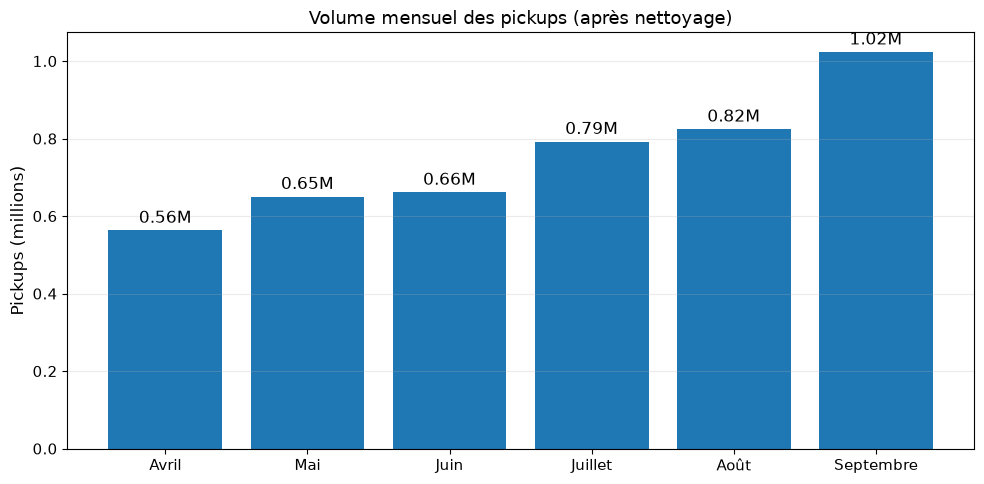

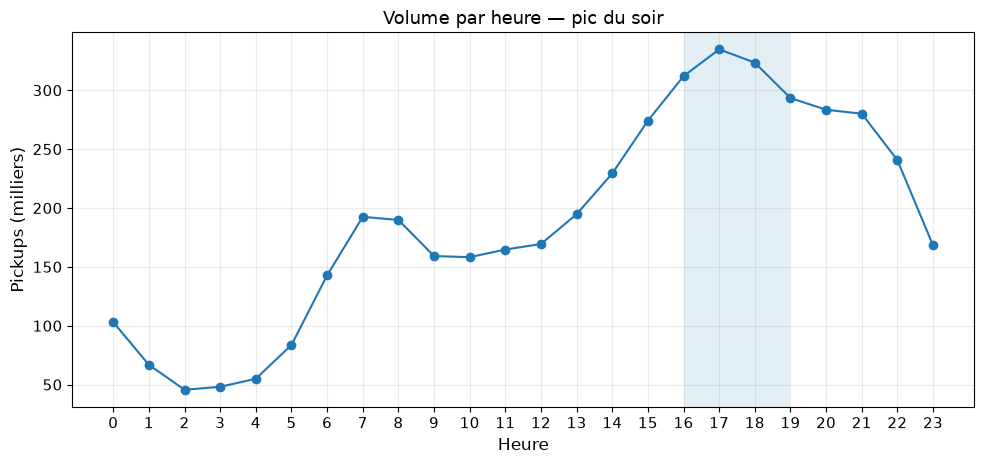

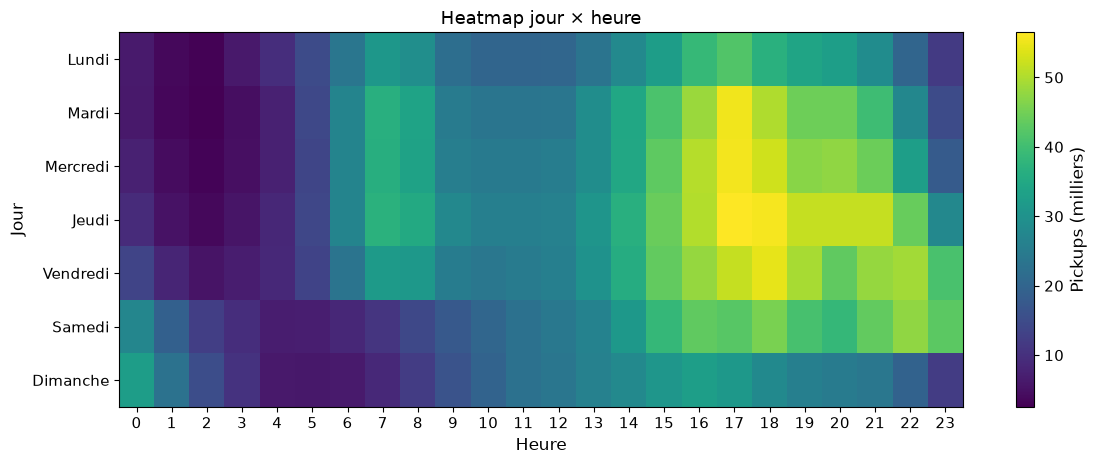

Top jour : {'weekday': 3, 'pickups': 752167, 'jour': 'Jeudi'}
Top heure : {'hour': 17, 'pickups': 334749}


In [4]:
month_labels = {4: "Avril", 5: "Mai", 6: "Juin", 7: "Juillet", 8: "Août", 9: "Septembre"}
weekday_fr = {
    0: "Lundi",
    1: "Mardi",
    2: "Mercredi",
    3: "Jeudi",
    4: "Vendredi",
    5: "Samedi",
    6: "Dimanche",
}

# Les trois comptages (mois, jour, heure) portent sur les MÊMES lignes : celles du jeu
# nettoyé `df` (et non sur `raw`), pour que leurs totaux soient cohérents.
monthly_counts = (
    df.groupby("month").size().reindex([4, 5, 6, 7, 8, 9]).rename("pickups").reset_index()
)
monthly_counts["mois"] = monthly_counts["month"].map(month_labels)
weekday_counts = df.groupby("weekday").size().reindex(range(7)).rename("pickups").reset_index()
weekday_counts["jour"] = weekday_counts["weekday"].map(weekday_fr)
hourly_counts = df.groupby("hour").size().reindex(range(24)).rename("pickups").reset_index()
weekday_hour = df.groupby(["weekday", "hour"]).size().reset_index(name="pickups")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(monthly_counts["mois"], monthly_counts["pickups"] / 1e6)
ax.set_title("Volume mensuel des pickups (après nettoyage)")
ax.set_ylabel("Pickups (millions)")
ax.grid(axis="y", alpha=0.25)
for i, v in enumerate(monthly_counts["pickups"] / 1e6):
    ax.text(i, v + 0.02, f"{v:.2f}M", ha="center")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(hourly_counts["hour"], hourly_counts["pickups"] / 1000, marker="o")
ax.axvspan(16, 19, alpha=0.12)
ax.set_title("Volume par heure — pic du soir")
ax.set_xlabel("Heure")
ax.set_ylabel("Pickups (milliers)")
ax.set_xticks(range(24))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

pivot = weekday_hour.pivot(index="weekday", columns="hour", values="pickups").reindex(range(7))
fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(pivot.values / 1000, aspect="auto", interpolation="nearest")
ax.set_title("Heatmap jour × heure")
ax.set_xlabel("Heure")
ax.set_ylabel("Jour")
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels([weekday_fr[i] for i in range(7)])
fig.colorbar(im, ax=ax, label="Pickups (milliers)")
plt.tight_layout()
plt.show()

print("Top jour :", weekday_counts.sort_values("pickups", ascending=False).iloc[0].to_dict())
print("Top heure :", hourly_counts.sort_values("pickups", ascending=False).iloc[0].to_dict())

## 5. Densité géographique

La demande est fortement concentrée à Manhattan, avec des poches secondaires à Brooklyn/Queens et aux aéroports. Cette structure justifie un algorithme de clustering géographique.

In [5]:
vis_sample = df.sample(n=min(350_000, len(df)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(9, 9))
hb = ax.hexbin(vis_sample["Lon"], vis_sample["Lat"], gridsize=185, mincnt=1, bins="log")
ax.set_title("Densité géographique des pickups — NYC")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-74.12, -73.70)
ax.set_ylim(40.55, 40.92)
fig.colorbar(hb, ax=ax, label="Densité relative (log)")
plt.tight_layout()
plt.show()

<Figure size 900x900 with 2 Axes>

## 6. Choix de l'algorithme

`MiniBatchKMeans` est retenu : il est adapté à plusieurs millions de points, produit des centroïdes directement actionnables et permet de réentraîner rapidement un modèle par créneau temporel.

Comparaison rapide :

- **KMeans / MiniBatchKMeans** : rapide, interprétable, mais suppose des zones plutôt convexes ;
- **DBSCAN** : détecte les zones denses et le bruit, mais son résultat dépend fortement du rayon `eps`. Ce n'est pas une affirmation de principe : un **test de sensibilité** est fait en section 9 ter (nombre de clusters, part de bruit et taille du plus grand cluster pour six valeurs de `eps`) ;
- **HDBSCAN** : intéressant en production, mais dépendance supplémentaire non nécessaire pour un MVP Scikit-Learn ; non testé ici.

**Nommer une zone.** Les noms sont des repères de lecture : chaque centroïde porte le nom du repère connu le plus proche. Ce repère peut être éloigné du centroïde ; la distance est conservée (`zone_distance_km`) et, au-delà de 3 km, le libellé le dit (« secteur de … »). **Classer une zone.** Le volume de pickups mélange l'étendue de la zone et sa densité : on calcule aussi la surface (disque de rayon p90) et la **densité** (pickups par km²), pour ne pas confondre une grande zone et une zone intense.

In [6]:
# Repères utilisés uniquement pour nommer les centroïdes de manière lisible.
landmarks = pd.DataFrame(
    [
        ("Midtown Manhattan / Times Square", 40.7580, -73.9855),
        ("Chelsea / Flatiron", 40.7411, -73.9897),
        ("Lower Manhattan / Financial District", 40.7075, -74.0113),
        ("Upper East Side", 40.7736, -73.9566),
        ("Upper West Side", 40.7870, -73.9754),
        ("Harlem / Upper Manhattan", 40.8116, -73.9465),
        ("Williamsburg / Greenpoint", 40.7143, -73.9575),
        ("Downtown Brooklyn / DUMBO", 40.6955, -73.9874),
        ("Astoria / Long Island City", 40.7549, -73.9340),
        ("LaGuardia Airport", 40.7769, -73.8740),
        ("JFK Airport", 40.6413, -73.7781),
        ("Newark / Jersey City", 40.7357, -74.1724),
        ("South Bronx", 40.8176, -73.9182),
    ],
    columns=["zone_name", "lat", "lon"],
)

# Au-delà de ce seuil, le repère le plus proche n'est plus un nom fiable : le libellé le dit.
SEUIL_NOM_KM = 3.0


# to_xy(lat, lon, lat0, lon0) est dans uber_bloc3.py (testée) : projection locale (kilomètres)
# d'un point latitude/longitude autour du centre (lat0, lon0). Sa réciproque est from_xy.
landmarks[["x_km", "y_km"]] = [
    to_xy(lat, lon, lat0, lon0)
    for lat, lon in zip(landmarks["lat"], landmarks["lon"], strict=True)
]


# from_xy(x, y, lat0, lon0), nearest_zone_name(lat, lon, landmarks, lat0, lon0) et fit_hotzones
# sont dans uber_bloc3.py (testées dans tests/) :
# - from_xy : opération inverse de to_xy, kilomètres → latitude/longitude ;
# - nearest_zone_name : nom du repère le plus proche d'un point, et distance en kilomètres ;
# - fit_hotzones : ajuste MiniBatchKMeans sur un sous-ensemble et rend (stats, modèle,
#   étiquettes, qualité). Les centroïdes portent le nom du repère le plus proche ; au-delà de
#   SEUIL_NOM_KM le libellé le dit. La surface (disque de rayon p90) et la densité évitent de
#   confondre une grande zone et une zone intense.
#
# Réglages de MiniBatchKMeans et tailles d'échantillon : ICI, pour pouvoir être changés en
# direct. Le modèle est ajusté sur au plus taille_apprentissage points, et sa qualité
# (silhouette, Davies-Bouldin, Calinski-Harabasz) mesurée sur au plus taille_qualite points.
TAILLE_APPRENTISSAGE = 50_000
TAILLE_QUALITE = 2_000
BATCH_SIZE = 5_000
N_INIT = 3
MAX_ITER = 80
ajuster_hotzones = partial(
    fit_hotzones,
    landmarks=landmarks,
    lat0=lat0,
    lon0=lon0,
    random_state=RANDOM_STATE,
    seuil_nom_km=SEUIL_NOM_KM,
    taille_apprentissage=TAILLE_APPRENTISSAGE,
    taille_qualite=TAILLE_QUALITE,
    batch_size=BATCH_SIZE,
    n_init=N_INIT,
    max_iter=MAX_ITER,
)


## 7. Choix du nombre de clusters

On cherche un compromis entre qualité statistique et interprétabilité métier. `k=8` est retenu pour les modèles par jour : il conserve une granularité quartier tout en évitant de fragmenter Manhattan en trop de micro-zones.

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,4,250246.547,0.429,0.815,1163.248
1,5,195550.844,0.454,0.807,1268.265
2,6,173606.156,0.390,0.761,1150.845
3,7,157470.578,0.406,0.762,1075.154
4,8,114012.789,0.492,0.644,1561.671
5,9,87917.602,0.412,0.652,1875.057
6,10,85921.305,0.395,0.793,1741.505


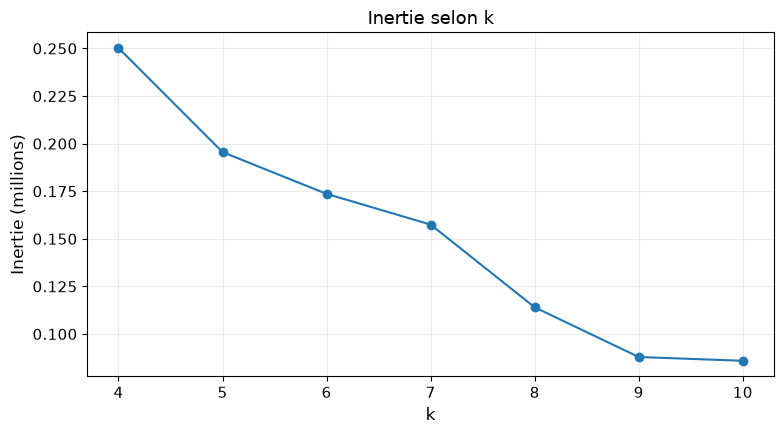

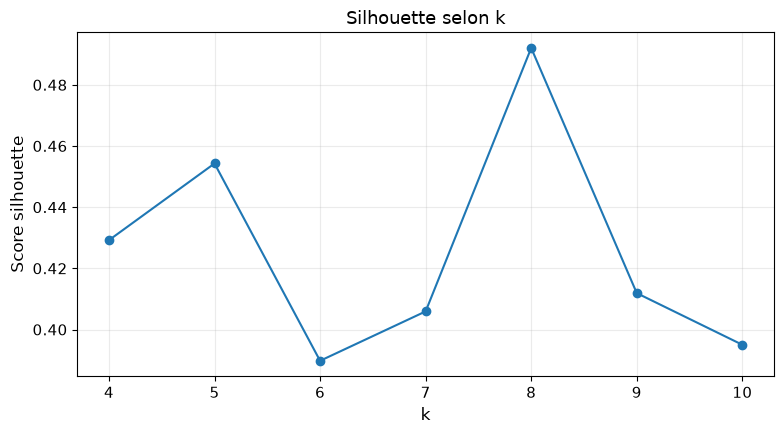

In [7]:
coords_sample = (
    df[["x_km", "y_km"]].sample(n=min(20_000, len(df)), random_state=RANDOM_STATE).to_numpy()
)
metric_idx = np.random.default_rng(RANDOM_STATE).choice(
    len(coords_sample), size=min(2_000, len(coords_sample)), replace=False
)
coords_metric = coords_sample[metric_idx]

metrics = []
for k in range(4, 11):
    model = MiniBatchKMeans(
        n_clusters=k, random_state=RANDOM_STATE, batch_size=5_000, n_init=3, max_iter=80
    )
    model.fit(coords_sample)
    labels_metric = model.predict(coords_metric)
    metrics.append(
        {
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(coords_metric, labels_metric),
            "davies_bouldin": davies_bouldin_score(coords_metric, labels_metric),
            "calinski_harabasz": calinski_harabasz_score(coords_metric, labels_metric),
        }
    )

metrics_df = pd.DataFrame(metrics)
afficher(metrics_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics_df["k"], metrics_df["inertia"] / 1e6, marker="o")
ax.set_title("Inertie selon k")
ax.set_xlabel("k")
ax.set_ylabel("Inertie (millions)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics_df["k"], metrics_df["silhouette"], marker="o")
ax.set_title("Silhouette selon k")
ax.set_xlabel("k")
ax.set_ylabel("Score silhouette")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Hot-zones par jour de semaine

On entraîne un modèle par jour de semaine pour obtenir les zones pertinentes à l'échelle hebdomadaire. Les noms de zones sont des labels de lecture associés au repère le plus proche du centroïde ; le modèle utilise uniquement les coordonnées.

In [8]:
K_DAY = 8
all_day_rows = []
quality_rows = []
for wd in range(7):
    subset = df[df["weekday"] == wd]
    stats, model, labels, quality = ajuster_hotzones(subset, k=K_DAY)
    stats.insert(0, "weekday", wd)
    stats.insert(1, "jour", weekday_fr[wd])
    all_day_rows.append(stats)
    quality.update({"weekday": wd, "jour": weekday_fr[wd]})
    quality_rows.append(quality)

daily_hotzones = pd.concat(all_day_rows, ignore_index=True)
daily_quality = pd.DataFrame(quality_rows)

# Table synthétique top 3 : « zone (part du jour, heure de pic) ».
summary_top3 = daily_hotzones[daily_hotzones["rank"] <= 3].copy()
summary_top3["hotzone_label"] = summary_top3.apply(
    lambda r: f"{r['zone_label']} ({r['share_pct']:.1f}%, pic {int(r['peak_hour']):02d}h)", axis=1
)
summary_pivot = summary_top3.pivot(index="jour", columns="rank", values="hotzone_label").reindex(
    [weekday_fr[i] for i in range(7)]
)
summary_pivot.columns = [f"Hot-zone #{i}" for i in summary_pivot.columns]

afficher(summary_pivot)
print("Qualité des 7 modèles journaliers :")
afficher(
    daily_quality[
        ["jour", "n_rows", "k", "silhouette", "davies_bouldin", "calinski_harabasz"]
    ].round(3)
)

# Distance entre chaque centroïde et le repère qui le nomme : les noms lointains sont signalés.
loin = daily_hotzones[daily_hotzones["zone_distance_km"] > SEUIL_NOM_KM]
print(
    f"Zones dont le repère le plus proche est à plus de {SEUIL_NOM_KM:.0f} km : "
    f"{len(loin)} sur {len(daily_hotzones)} (distance maximale : "
    f"{daily_hotzones['zone_distance_km'].max():.1f} km)."
)
n_top3_loin = int((summary_top3["zone_distance_km"] > SEUIL_NOM_KM).sum())
print(
    f"Parmi les 3 premières zones de chaque jour : {n_top3_loin} à plus de {SEUIL_NOM_KM:.0f} km."
)

,Hot-zone #1,Hot-zone #2,Hot-zone #3
jour,,,
Lundi,"Midtown Manhattan / Times Square (31.9%, pic 17h)","Chelsea / Flatiron (26.2%, pic 17h)","Lower Manhattan / Financial District (13.8%, p..."
Mardi,"Midtown Manhattan / Times Square (40.7%, pic 17h)","Chelsea / Flatiron (33.4%, pic 17h)","Harlem / Upper Manhattan (8.6%, pic 07h)"
Mercredi,"Midtown Manhattan / Times Square (42.9%, pic 17h)","Chelsea / Flatiron (38.1%, pic 17h)","Downtown Brooklyn / DUMBO (9.1%, pic 21h)"
Jeudi,"Midtown Manhattan / Times Square (38.3%, pic 17h)","Chelsea / Flatiron (33.9%, pic 21h)","Upper West Side (10.7%, pic 07h)"
Vendredi,"Midtown Manhattan / Times Square (33.0%, pic 18h)","Chelsea / Flatiron (31.7%, pic 22h)","Upper East Side (18.4%, pic 18h)"
Samedi,"Chelsea / Flatiron (40.3%, pic 22h)","Midtown Manhattan / Times Square (29.7%, pic 18h)","Downtown Brooklyn / DUMBO (9.4%, pic 21h)"
Dimanche,"Chelsea / Flatiron (44.8%, pic 00h)","Upper East Side (27.0%, pic 16h)","Downtown Brooklyn / DUMBO (11.1%, pic 00h)"


Qualité des 7 modèles journaliers :


,jour,n_rows,k,silhouette,davies_bouldin,calinski_harabasz
0,Lundi,539177,8,0.385,0.723,1945.939
1,Mardi,661272,8,0.447,0.683,1450.914
2,Mercredi,693720,8,0.488,0.641,1451.905
3,Jeudi,752167,8,0.455,0.680,1432.888
4,Vendredi,737468,8,0.382,0.643,1650.875
5,Samedi,641846,8,0.425,0.716,1076.973
6,Dimanche,487450,8,0.447,0.697,1607.757


Zones dont le repère le plus proche est à plus de 3 km : 11 sur 56 (distance maximale : 7.9 km).
Parmi les 3 premières zones de chaque jour : 0 à plus de 3 km.


## 8 bis. Cartes des hot-zones : une par jour de la semaine

L'énoncé demande les hot-zones **au moins par jour de la semaine**, avec une carte. Voici une petite carte par jour : les points gris sont un échantillon des pickups du jour, les cercles sont les centroïdes des 8 zones (surface proportionnelle à leur part des pickups du jour) et les numéros désignent les trois premières zones par volume.

In [9]:
# =============================================================================
# 8 bis. Sept cartes : une par jour de la semaine
# =============================================================================
# Pour chaque jour : un échantillon de 15 000 pickups (fond gris), les 8 centroïdes du
# modèle journalier (cercles), les trois premières zones numérotées. La huitième case de
# la grille porte la légende. La figure est dessinée à la taille où elle est lue (10,4 po de
# large) : les polices de 11 à 12 pt restent lisibles sans agrandissement. Les étiquettes
# sont placées par calcul, au plus près de leur cercle, à un endroit où elles ne recouvrent
# ni un cercle ni une autre étiquette ; un trait fin les relie à leur cercle.
NOMS_CARTES = {
    "Midtown Manhattan / Times Square": "Midtown",
    "Chelsea / Flatiron": "Chelsea",
    "Lower Manhattan / Financial District": "Lower Manh.",
    "Downtown Brooklyn / DUMBO": "Brooklyn",
    "Harlem / Upper Manhattan": "Harlem",
    "Upper West Side": "Upper West",
    "Upper East Side": "Upper East",
}
CAR_PAR_CASE = 0.040  # largeur d'un caractère, en fraction de la largeur d'une case (11 pt gras)


# distance_au_segment, chercher_position et placer_etiquette sont dans uber_bloc3.py (testées
# dans tests/). placer_etiquette(centre, largeur, occupes, cercles, GEOMETRIE) cherche d'abord
# une position dont le trait de rappel ne traverse aucun autre cercle ; à défaut, accepte un
# trait qui en traverse un (l'étiquette ne recouvre jamais un cercle).
# GEOMETRIE regroupe les réglages du placement, en fraction de la case : zone de recherche et pas
# (x puis y), demi-hauteur d'une étiquette, marges autour d'elle, distance minimale du trait.
GEOMETRIE = GeometrieCarte(
    x_min=0.02,
    x_max=0.99,
    pas_x=0.02,
    y_min=0.06,
    y_max=0.95,
    pas_y=0.03,
    demi_hauteur=0.045,
    marge_x=0.035,
    marge_y=0.045,
    distance_trait=0.04,
)


fig, axes = plt.subplots(2, 4, figsize=(10.4, 5.4))
for wd, ax in zip(range(7), axes.flat[:7], strict=True):
    fond = df.loc[df["weekday"] == wd, ["Lon", "Lat"]].sample(n=15_000, random_state=RANDOM_STATE)
    ax.scatter(fond["Lon"], fond["Lat"], s=0.6, alpha=0.15, color="gray")
    zones_jour = daily_hotzones[daily_hotzones["weekday"] == wd]
    ax.scatter(
        zones_jour["centroid_lon"],
        zones_jour["centroid_lat"],
        s=20 + zones_jour["share_pct"] * 8,
        c=np.where(zones_jour["rank"] <= 3, "tab:red", "tab:blue"),
        edgecolors="black",
        linewidths=0.7,
        zorder=3,
    )
    ax.set_xlim(-74.10, -73.72)
    ax.set_ylim(40.58, 40.90)
    ax.set_xticks([])
    ax.set_yticks([])
    # Les limites étant fixées, on convertit les centroïdes en fraction des axes.
    cercles = [
        tuple(ax.transLimits.transform((lon, lat)))
        for lon, lat in zip(zones_jour["centroid_lon"], zones_jour["centroid_lat"], strict=True)
    ]
    occupes: list[tuple[float, float, float, float]] = []
    for _, zone in zones_jour[zones_jour["rank"] <= 3].iterrows():
        nom = NOMS_CARTES.get(zone["zone_name"], zone["zone_name"].split("/")[0].strip())
        texte = f"{int(zone['rank'])}. {nom}"
        largeur = CAR_PAR_CASE * len(texte)
        centre = tuple(ax.transLimits.transform((zone["centroid_lon"], zone["centroid_lat"])))
        position = placer_etiquette(centre, largeur, occupes, cercles, GEOMETRIE)
        if position is None:
            continue
        occupes.append(
            (position[0], position[1] - 0.045, position[0] + largeur, position[1] + 0.045)
        )
        ax.annotate(
            texte,
            xy=(zone["centroid_lon"], zone["centroid_lat"]),
            xytext=position,
            textcoords="axes fraction",
            fontsize=11,
            weight="bold",
            va="center",
            ha="left",
            arrowprops={"arrowstyle": "-", "color": "black", "linewidth": 0.7, "shrinkB": 5},
            bbox={"boxstyle": "round,pad=0.12", "facecolor": "white", "edgecolor": "none"},
            zorder=5,
        )
    premiere = zones_jour.sort_values("rank").iloc[0]
    ax.set_title(f"{weekday_fr[wd]} : n° 1 = {premiere['share_pct']:.0f} %", fontsize=12)
axes.flat[7].axis("off")
axes.flat[7].text(
    0.0,
    0.5,
    "Gris : pickups du jour\n(échantillon)\n\nRouge : 3 premières zones\npar volume\n\n"
    "Bleu : 5 autres zones\n\nSurface du cercle :\npart des pickups du jour",
    fontsize=11,
    va="center",
)
fig.tight_layout()
plt.show()
plt.close(fig)

<Figure size 1040x540 with 8 Axes>

## 9. Démonstration : recommandations pour vendredi à 18h

Le créneau vendredi 18h est un cas métier pertinent : il correspond à une forte demande de fin de journée. Le modèle retourne les hot-zones triées par volume historique.

In [10]:
# Choix du nombre de zones pour le créneau vendredi 18 h.
# Même démarche qu'en section 7 : silhouette et Davies-Bouldin pour plusieurs k, mesurés sur
# un échantillon de 2 000 points ; K_HOUR est le k de silhouette maximale, et l'on vérifie
# que Davies-Bouldin est d'accord. Rien n'est choisi à la main.
fri18 = df[(df["weekday"] == 4) & (df["hour"] == 18)]
coords_fri18 = fri18[["x_km", "y_km"]].to_numpy(dtype=np.float32)
echantillon_fri18 = np.random.default_rng(RANDOM_STATE).choice(
    len(coords_fri18), size=min(2_000, len(coords_fri18)), replace=False
)
lignes_k_heure = []
for k_test in range(3, 11):
    modele_k = MiniBatchKMeans(
        n_clusters=k_test, random_state=RANDOM_STATE, batch_size=5_000, n_init=3, max_iter=80
    )
    modele_k.fit(coords_fri18)
    etiquettes_k = modele_k.predict(coords_fri18[echantillon_fri18])
    lignes_k_heure.append(
        {
            "k": k_test,
            "silhouette": silhouette_score(coords_fri18[echantillon_fri18], etiquettes_k),
            "davies_bouldin": davies_bouldin_score(coords_fri18[echantillon_fri18], etiquettes_k),
        }
    )
k_heure = pd.DataFrame(lignes_k_heure)
afficher(k_heure.round(3))
K_HOUR = int(k_heure.loc[k_heure["silhouette"].idxmax(), "k"])
k_db_heure = int(k_heure.loc[k_heure["davies_bouldin"].idxmin(), "k"])
print(
    f"K_HOUR = {K_HOUR} (silhouette maximale) ; Davies-Bouldin minimal pour k = {k_db_heure} : "
    + ("les deux mesures s'accordent." if K_HOUR == k_db_heure else "les deux mesures divergent.")
)

fri18_stats, fri18_model, fri18_labels, fri18_quality = ajuster_hotzones(fri18, k=K_HOUR)

afficher(
    fri18_stats[
        [
            "rank",
            "zone_label",
            "pickup_count",
            "share_pct",
            "density_per_km2",
            "rank_density",
            "peak_hour",
            "centroid_lat",
            "centroid_lon",
            "radius_p90_km",
        ]
    ].round(3)
)
print(
    "Qualité modèle vendredi 18h :",
    {k: round(v, 3) if isinstance(v, float) else v for k, v in fri18_quality.items()},
)
print(
    "Classement par volume (rank) et par densité (rank_density) : le volume favorise les grandes "
    "zones, la densité les zones compactes ; les deux lectures sont données."
)

fri18_vis = fri18.sample(n=min(70_000, len(fri18)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(12, 7.2))
ax.scatter(fri18_vis["Lon"], fri18_vis["Lat"], s=1.2, alpha=0.18)
for _, r in fri18_stats.iterrows():
    size = 80 + r["share_pct"] * 18
    ax.scatter(
        r["centroid_lon"], r["centroid_lat"], s=size, edgecolors="black", linewidths=0.9, zorder=3
    )
    name = r["zone_name"].split("/")[0].strip().replace("Midtown Manhattan", "Midtown")
    ax.text(
        r["centroid_lon"] + 0.006,
        r["centroid_lat"] + 0.006,
        f"#{int(r['rank'])} {name}\n{r['share_pct']:.1f}%",
        fontsize=12,
        weight="bold",
        zorder=4,
    )
ax.set_title("Hot-zones détectées — vendredi 18h")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-74.21, -73.72)
ax.set_ylim(40.58, 40.91)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()
plt.close(fig)

,k,silhouette,davies_bouldin
0,3,0.443,0.711
1,4,0.437,0.815
2,5,0.410,0.785
3,6,0.450,0.624
4,7,0.376,0.765
5,8,0.326,0.765
6,9,0.316,0.906
7,10,0.331,0.712


K_HOUR = 6 (silhouette maximale) ; Davies-Bouldin minimal pour k = 6 : les deux mesures s'accordent.


,rank,zone_label,pickup_count,share_pct,density_per_km2,rank_density,peak_hour,centroid_lat,centroid_lon,radius_p90_km
0,1,Chelsea / Flatiron,24991,45.827,1864.691,1,18,40.748,-73.987,2.065
1,2,Downtown Brooklyn / DUMBO,15571,28.553,247.369,3,18,40.708,-73.990,4.476
2,3,Upper East Side,11058,20.278,335.669,2,18,40.776,-73.964,3.238
3,4,LaGuardia Airport,1587,2.910,4.403,5,18,40.782,-73.861,10.711
4,5,JFK Airport,945,1.733,5.493,4,18,40.654,-73.787,7.400
5,6,secteur de Newark / Jersey City (à 3.8 km),381,0.699,1.547,6,18,40.702,-74.178,8.853


Qualité modèle vendredi 18h : {'n_rows': 54533, 'k': 6, 'silhouette': 0.366, 'davies_bouldin': 0.693, 'calinski_harabasz': 1222.486, 'inertia': 315368.969}
Classement par volume (rank) et par densité (rank_density) : le volume favorise les grandes zones, la densité les zones compactes ; les deux lectures sont données.


<Figure size 1200x720 with 1 Axes>

## 9 ter. Test de sensibilité de DBSCAN

La section 6 écarte DBSCAN parce que son résultat dépend de `eps`. Voici la mesure, sur le créneau vendredi 18 h (30 000 points tirés au hasard, `min_samples=50`, distances en kilomètres) : pour chaque `eps`, le nombre de clusters, la part de points classés comme bruit et la part du plus grand cluster.

In [11]:
# =============================================================================
# 9 ter. DBSCAN : sensibilité au rayon eps (justifie le choix de MiniBatchKMeans)
# =============================================================================
# DBSCAN regroupe les points assez proches les uns des autres (rayon eps) et laisse les
# autres en « bruit ». Il n'a pas de paramètre k, mais il a eps : si le résultat change
# beaucoup avec eps, le calibrage devient une décision difficile à justifier.
echantillon_dbscan = coords_fri18[
    np.random.default_rng(RANDOM_STATE).choice(
        len(coords_fri18), size=min(30_000, len(coords_fri18)), replace=False
    )
]
lignes_dbscan = []
for eps in [0.1, 0.2, 0.3, 0.5, 0.8, 1.2]:
    etiquettes_db = DBSCAN(eps=eps, min_samples=50).fit(echantillon_dbscan).labels_
    appartenance = pd.Series(etiquettes_db[etiquettes_db >= 0])
    lignes_dbscan.append(
        {
            "eps (km)": eps,
            "nombre de clusters": appartenance.nunique(),
            "part de bruit (%)": 100 * float((etiquettes_db == -1).mean()),
            "part du plus grand cluster (%)": 100
            * float(appartenance.value_counts(normalize=True).iloc[0])
            if len(appartenance)
            else 0.0,
        }
    )
sensibilite_dbscan = pd.DataFrame(lignes_dbscan)
afficher(sensibilite_dbscan.round(1))

n_min = int(sensibilite_dbscan["nombre de clusters"].min())
n_max = int(sensibilite_dbscan["nombre de clusters"].max())
grand_min = sensibilite_dbscan["part du plus grand cluster (%)"].min()
grand_max = sensibilite_dbscan["part du plus grand cluster (%)"].max()
afficher_markdown(
    f"""
**Lecture.** Quand `eps` passe de {sensibilite_dbscan["eps (km)"].min()} à
{sensibilite_dbscan["eps (km)"].max()} km, le nombre de clusters varie de {n_min} à {n_max} et le
plus grand cluster regroupe de {grand_min:.0f} % à {grand_max:.0f} % des points : le résultat
dépend fortement de `eps`, sans valeur qui s'impose. Avec MiniBatchKMeans, le nombre de zones
est choisi (sections 7 et 9) et les centroïdes sont directement exploitables : c'est pourquoi il
est retenu. Ce test porte sur un créneau et un
échantillon ; il justifie un choix de MVP, il ne prouve pas que DBSCAN serait inutilisable avec un
calibrage plus soigné (HDBSCAN reste une piste, non testée).
"""
)

,eps (km),nombre de clusters,part de bruit (%),part du plus grand cluster (%)
0,0.1,49,48.5,52.0
1,0.2,19,17.2,92.6
2,0.3,10,12.8,91.6
3,0.5,9,6.7,86.5
4,0.8,5,3.8,95.7
5,1.2,4,2.7,97.3



**Lecture.** Quand `eps` passe de 0.1 à
1.2 km, le nombre de clusters varie de 4 à 49 et le
plus grand cluster regroupe de 52 % à 97 % des points : le résultat
dépend fortement de `eps`, sans valeur qui s'impose. Avec MiniBatchKMeans, le nombre de zones
est choisi (sections 7 et 9) et les centroïdes sont directement exploitables : c'est pourquoi il
est retenu. Ce test porte sur un créneau et un
échantillon ; il justifie un choix de MVP, il ne prouve pas que DBSCAN serait inutilisable avec un
calibrage plus soigné (HDBSCAN reste une piste, non testée).


## 10. Fonction de recommandation réutilisable

La fonction suivante généralise le raisonnement : elle filtre un jour et une heure, entraîne le clustering sur ce créneau et retourne les `top_n` hot-zones classées par demande historique.

In [12]:
# recommend_hotzones_from_history(weekday, hour, top_n, daily_hotzones, fri18_stats) est dans
# uber_bloc3.py (testée) : elle retourne les hot-zones déjà calculées.
# - Si hour est None : modèle journalier, adapté au livrable « hot-zones par jour ».
# - Si weekday = 4 et hour = 18 : exemple de créneau horaire détaillé dans ce notebook.
# - Pour tout autre créneau, appliquer ajuster_hotzones(df[(df.weekday == weekday) &
#   (df.hour == hour)], k=6).


# Exemple réutilisable sans réentraînement : vendredi 18h.
reco = recommend_hotzones_from_history(4, 18, 5, daily_hotzones, fri18_stats)
afficher(reco.round(3))

# Exemple journalier : lundi, toutes heures confondues.
afficher(recommend_hotzones_from_history(0, None, 5, daily_hotzones, fri18_stats).round(3))

,rank,zone_name,pickup_count,share_pct,centroid_lat,centroid_lon,radius_p90_km
0,1,Chelsea / Flatiron,24991,45.827,40.748,-73.987,2.065
1,2,Downtown Brooklyn / DUMBO,15571,28.553,40.708,-73.990,4.476
2,3,Upper East Side,11058,20.278,40.776,-73.964,3.238
3,4,LaGuardia Airport,1587,2.910,40.782,-73.861,10.711
4,5,JFK Airport,945,1.733,40.654,-73.787,7.400


,rank,zone_name,pickup_count,share_pct,centroid_lat,centroid_lon,radius_p90_km
0,1,Midtown Manhattan / Times Square,171732,31.851,40.760,-73.978,2.058
1,2,Chelsea / Flatiron,141059,26.162,40.736,-73.993,1.953
2,3,Lower Manhattan / Financial District,74317,13.783,40.714,-74.004,1.918
3,4,Upper West Side,49580,9.195,40.795,-73.955,4.674
4,5,Downtown Brooklyn / DUMBO,48285,8.955,40.682,-73.962,5.416


## 10 bis. Prévision supervisée de la demande par hot-zone

**Pourquoi cette section ?** Le clustering dit **où** se trouve la demande. Un chauffeur a aussi besoin de savoir **combien** de courses attendre dans une zone à une heure donnée : c'est l'objet du sujet *Uber Pickups — demand forecasting*. Cette section transforme les hot-zones en un problème supervisé et couvre les exigences du référentiel qu'un clustering seul ne peut pas couvrir :

| Exigence du référentiel (RNCP35288, bloc 3) | Où, dans cette section |
|---|---|
| C3.1 — pipeline Scikit-Learn pour « encoder, normaliser et découper des données » | 10 bis.1 (`Pipeline` de zonage), 10 bis.2 (encodage cyclique, données rangées par heure), 10 bis.3 (découpage temporel), 10 bis.4 (`ColumnTransformer` : `OneHotEncoder`, `StandardScaler`) |
| C3.2 — algorithmes supervisés adaptés | 10 bis.4 : `Ridge` et `HistGradientBoostingRegressor` |
| Critère — « K-Fold Crossvalidation et tests de vérification de sur-entraînement et sous-entraînement » | 10 bis.4 (`TimeSeriesSplit`, 5 plis, périodes affichées) et 10 bis.5 |
| Critère — « comparaison du nouveau modèle par rapport à ce qu'il y a déjà en place » | 10 bis.4 et 10 bis.5 : prévision « comme la semaine dernière », erreurs globales **et par zone** (MAE, WAPE, biais) |
| C3.4 — « l'influence des différentes variables » | 10 bis.6 : importance par permutation |
| Livrable — « recommandations sur les prédictions obtenues » | 10 bis.7 |

**Indicateurs.** La MAE est l'erreur absolue moyenne, en courses par zone et par heure. Le **WAPE** (weighted absolute percentage error) est la somme des erreurs absolues divisée par la demande totale : une erreur en pourcentage qui reste lisible quand certaines zones ont très peu de courses. Le **biais** est la somme des erreurs signées divisée par la demande totale : négatif, le modèle sous-estime en moyenne.

In [13]:
# =============================================================================
# 10 bis.1 — Zonage reproductible : un Pipeline Scikit-Learn (C3.1)
# =============================================================================
# Les modèles des sections 8 et 9 sont entraînés jour par jour. Pour PRÉVOIR la
# demande, il faut au contraire UNE carte de zones commune à toute la période :
# sinon la « zone 3 » de lundi ne serait pas la « zone 3 » de mardi.
#
# Le Pipeline enchaîne deux étapes :
#   1. « projection_km » : latitude/longitude → kilomètres. C'est la
#      NORMALISATION adaptée à des coordonnées : elle met les deux axes dans la
#      même unité physique, ce qui rend la distance euclidienne de KMeans
#      interprétable. Un StandardScaler déformerait la carte : il diviserait
#      l'axe est-ouest et l'axe nord-sud par deux écarts-types différents.
#   2. « kmeans » : MiniBatchKMeans, même algorithme et même k que la section 8.
# Avantage : la même transformation s'applique à l'apprentissage et à la
# prédiction, sans risque d'oubli ni de fuite.


# projeter_en_km(coords, lat0, lon0) est dans uber_bloc3.py (testée) : elle convertit un tableau
# [[lat, lon], ...] en [[x_km, y_km], ...], avec la même formule que la section 3 (projection
# locale autour du centre de New York). lat0 et lon0 lui arrivent par kw_args, ce qui garde le
# transformateur clonable dans le Pipeline.


zonage = Pipeline(
    [
        (
            "projection_km",
            FunctionTransformer(projeter_en_km, kw_args={"lat0": lat0, "lon0": lon0}),
        ),
        (
            "kmeans",
            MiniBatchKMeans(
                n_clusters=K_DAY, random_state=RANDOM_STATE, batch_size=10_000, n_init=3
            ),
        ),
    ]
)

# Apprentissage sur 300 000 courses tirées au hasard, UNIQUEMENT parmi celles d'avril à
# août : septembre est la période de TEST de la prévision (section 10 bis.3), donc le zonage
# ne doit pas l'avoir vue. 300 000 courses suffisent largement à placer 8 centroïdes.
echantillon = df.loc[df["month"] <= 8, ["Lat", "Lon"]].sample(n=300_000, random_state=RANDOM_STATE)
zonage.fit(echantillon.to_numpy())

# Chaque course (de toute la période) est affectée à la zone de centroïde le plus proche.
df["zone"] = zonage.predict(df[["Lat", "Lon"]].to_numpy()).astype("int8")

# Lecture métier : chaque zone porte le nom du repère le plus proche.
centres_km = zonage.named_steps["kmeans"].cluster_centers_
noms_zones = {
    i: nearest_zone_name(*from_xy(x, y, lat0, lon0), landmarks, lat0, lon0)[0]
    for i, (x, y) in enumerate(centres_km)
}
parts = df["zone"].value_counts(normalize=True).reindex(range(K_DAY), fill_value=0)
afficher(
    pd.DataFrame(
        {
            "zone": range(K_DAY),
            "repère le plus proche": [noms_zones[i] for i in range(K_DAY)],
            "part des courses (%)": (100 * parts.values).round(1),
        }
    )
)

,zone,repère le plus proche,part des courses (%)
0,0,Midtown Manhattan / Times Square,35.4
1,1,LaGuardia Airport,3.6
2,2,Chelsea / Flatiron,33.2
3,3,JFK Airport,2.8
4,4,Upper East Side,13.7
5,5,Newark / Jersey City,0.9
6,6,Downtown Brooklyn / DUMBO,9.3
7,7,South Bronx,1.3


In [14]:
# =============================================================================
# 10 bis.2 — Table de demande et variables explicatives
# =============================================================================
# Cible : le nombre de courses (« pickups ») dans une zone pendant une heure.
# Les heures sans aucune course reçoivent un zéro explicite : une absence de
# course est une information (demande nulle), pas une donnée manquante.
df["heure_pleine"] = df["datetime"].dt.floor("h")
comptes = df.groupby(["zone", "heure_pleine"]).size().rename("pickups")
grille = pd.MultiIndex.from_product(
    [range(K_DAY), pd.date_range(df["heure_pleine"].min(), df["heure_pleine"].max(), freq="h")],
    names=["zone", "heure_pleine"],
)
demande = comptes.reindex(grille, fill_value=0).reset_index()

# Variables de calendrier.
demande["heure"] = demande["heure_pleine"].dt.hour
demande["jour_semaine"] = demande["heure_pleine"].dt.dayofweek
demande["mois"] = demande["heure_pleine"].dt.month
demande["week_end"] = demande["jour_semaine"].isin([5, 6]).astype(int)

# ENCODAGE CYCLIQUE de l'heure : 23 h et 0 h sont voisines dans la réalité,
# mais éloignées si l'on garde l'heure brute (0 à 23). Le couple (sinus,
# cosinus) place les 24 heures sur un cercle et restitue ce voisinage.
demande["heure_sin"] = np.sin(2 * np.pi * demande["heure"] / 24)
demande["heure_cos"] = np.cos(2 * np.pi * demande["heure"] / 24)

# RETARDS (« lags ») : la meilleure information sur la demande d'une heure est
# la demande de la veille et de la semaine précédente, à la même heure.
# Calculés zone par zone sur des données strictement PASSÉES : aucune
# information du futur n'entre dans les variables (pas de fuite de données).
demande = demande.sort_values(["zone", "heure_pleine"])
par_zone = demande.groupby("zone")["pickups"]
demande["retard_24h"] = par_zone.shift(24)
demande["retard_168h"] = par_zone.shift(168)
demande["moyenne_7j_meme_heure"] = demande.groupby(["zone", "heure"])["pickups"].transform(
    lambda s: s.shift(1).rolling(7).mean()
)

# Les premiers jours n'ont pas encore d'historique : on les retire.
demande = demande.dropna(subset=["retard_24h", "retard_168h", "moyenne_7j_meme_heure"])

# RANGEMENT PAR HEURE (essentiel pour la validation croisée temporelle).
# Les retards ont été calculés zone par zone, donc le tableau est rangé par zone puis par
# heure. TimeSeriesSplit coupe le tableau en blocs successifs de LIGNES : si les lignes sont
# rangées par zone, chaque « pli » est un bloc de zones et non une période, et la validation
# croisée ne mesure plus une prévision dans le temps. On range donc par heure, puis par zone :
# chaque bloc de lignes est alors une période.
demande = demande.sort_values(["heure_pleine", "zone"]).reset_index(drop=True)
print(f"Table de demande : {len(demande):,} lignes (zone × heure)".replace(",", " "))

Table de demande : 33 784 lignes (zone × heure)


In [15]:
# =============================================================================
# 10 bis.3 — DÉCOUPAGE temporel (C3.1)
# =============================================================================
# Un découpage aléatoire mélangerait passé et futur : le modèle verrait des
# heures de septembre pendant l'apprentissage, et son score serait trop
# optimiste. On respecte donc l'ordre du temps :
#   - apprentissage : avril → août 2014 ;
#   - test          : septembre 2014, jamais vu pendant l'apprentissage
#                     (ni par le modèle, ni par le zonage de la section 10 bis.1).
VARIABLES = [
    "zone",
    "jour_semaine",
    "week_end",
    "heure_sin",
    "heure_cos",
    "retard_24h",
    "retard_168h",
    "moyenne_7j_meme_heure",
]
apprentissage = demande[demande["mois"] <= 8].reset_index(drop=True)
jeu_test = demande[demande["mois"] == 9].reset_index(drop=True)
X_app, y_app = apprentissage[VARIABLES], apprentissage["pickups"]
X_test, y_test = jeu_test[VARIABLES], jeu_test["pickups"]
print(f"Apprentissage : {len(X_app):,} lignes | test : {len(X_test):,} lignes".replace(",", " "))

# Contrôles : (1) tout le test est postérieur à tout l'apprentissage ; (2) chaque heure
# compte exactement une ligne par zone, donc les plis de la validation croisée (qui
# découpent en blocs de lignes) tombent sur des frontières d'heures complètes.
assert apprentissage["heure_pleine"].max() < jeu_test["heure_pleine"].min()
assert (apprentissage.groupby("heure_pleine").size() == K_DAY).all()
assert apprentissage["heure_pleine"].is_monotonic_increasing
print(
    "Apprentissage :",
    apprentissage["heure_pleine"].min(),
    "→",
    apprentissage["heure_pleine"].max(),
)
print("Test          :", jeu_test["heure_pleine"].min(), "→", jeu_test["heure_pleine"].max())

Apprentissage : 28 032 lignes | test : 5 752 lignes
Apprentissage : 2014-04-08 00:00:00 → 2014-08-31 23:00:00
Test          : 2014-09-01 00:00:00 → 2014-09-30 22:00:00


In [16]:
# =============================================================================
# 10 bis.4 — Modèle en place, modèles supervisés, validation croisée temporelle
# =============================================================================
# --- Préparation commune (C3.1 : encoder, normaliser) ------------------------
# - zone et jour de la semaine sont des CATÉGORIES (la zone 6 n'est pas « deux
#   fois » la zone 3) → encodage one-hot ;
# - les variables numériques sont STANDARDISÉES (moyenne 0, écart-type 1),
#   indispensable pour Ridge, dont la pénalité suppose des échelles comparables.
preparation = ColumnTransformer(
    [
        ("categories", OneHotEncoder(handle_unknown="ignore"), ["zone", "jour_semaine"]),
        (
            "numeriques",
            StandardScaler(),
            [
                "week_end",
                "heure_sin",
                "heure_cos",
                "retard_24h",
                "retard_168h",
                "moyenne_7j_meme_heure",
            ],
        ),
    ]
)


# indicateurs(y_reel, y_prevu) et evaluer(nom, y_reel, y_prevu, y_app_reel, y_app_prevu) sont
# dans uber_bloc3.py (testées dans tests/) :
# - indicateurs : MAE (courses/heure), WAPE et biais (en % de la demande réelle totale).
#   WAPE = somme des erreurs absolues / somme de la demande. Biais = somme des erreurs signées
#   (prévu − réel) / somme de la demande : négatif = sous-estimation ;
# - evaluer : une ligne de tableau, R² (part de la variance expliquée, 1 = parfait), MAE, WAPE,
#   biais, et le R² d'apprentissage si on le demande.


# --- Le « modèle en place » ----------------------------------------------------
# Sans machine learning, un dispatcher prévoirait : « autant de courses que la
# semaine dernière, même jour, même heure, même zone ». C'est la prévision
# naïve saisonnière : la référence que le modèle doit battre.
NOM_REFERENCE = "Modèle en place : comme la semaine précédente"
resultats = [evaluer(NOM_REFERENCE, y_test, X_test["retard_168h"])]

# --- Deux modèles supervisés -----------------------------------------------------
modeles = {
    # Ridge : régression linéaire régularisée (pénalité L2), simple et lisible.
    "Ridge (linéaire régularisé)": Ridge(alpha=1.0),
    # Gradient boosting d'histogrammes : capte les interactions non linéaires
    # (l'effet de l'heure n'est pas le même dans toutes les zones).
    "Gradient boosting (HistGradientBoosting)": HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.06, random_state=RANDOM_STATE
    ),
}

# --- VALIDATION CROISÉE TEMPORELLE à 5 plis sur la seule période d'apprentissage -----
# TimeSeriesSplit est la variante temporelle de la K-Fold : chaque pli apprend sur le passé
# et se teste sur la période qui suit immédiatement. Les données étant rangées par heure
# (10 bis.2), chaque pli est bien une PÉRIODE : on l'affiche et on le vérifie.
validation_croisee = TimeSeriesSplit(n_splits=5)
lignes_plis = []
for numero_pli, (idx_app, idx_val) in enumerate(validation_croisee.split(X_app), start=1):
    heures_app = apprentissage["heure_pleine"].iloc[idx_app]
    heures_val = apprentissage["heure_pleine"].iloc[idx_val]
    assert heures_app.max() < heures_val.min()  # le passé précède toujours la validation
    reference_pli = indicateurs(y_app.iloc[idx_val], X_app["retard_168h"].iloc[idx_val])
    lignes_plis.append(
        {
            "pli": numero_pli,
            "apprentissage jusqu'au": heures_app.max().date(),
            "validation du": heures_val.min().date(),
            "validation au": heures_val.max().date(),
            "R² référence": r2_score(y_app.iloc[idx_val], X_app["retard_168h"].iloc[idx_val]),
            "MAE référence": reference_pli["MAE"],
        }
    )
plis = pd.DataFrame(lignes_plis)
print("Les 5 plis de la validation croisée temporelle (périodes consécutives) :")
afficher(plis.round(3))

# Ligne de la référence « comme la semaine précédente », calculée sur les MÊMES plis : le
# tableau compare ainsi les trois prévisions à égalité.
lignes_cv = [
    {
        "modèle": NOM_REFERENCE,
        "R² validation (moyenne 5 plis)": plis["R² référence"].mean(),
        "écart-type entre plis": plis["R² référence"].std(ddof=0),
        "R² du pli le plus bas": plis["R² référence"].min(),
        "R² du pli le plus haut": plis["R² référence"].max(),
        "MAE validation (moyenne 5 plis)": plis["MAE référence"].mean(),
        "R² apprentissage (moyenne)": np.nan,
    }
]
pipelines = {}
for nom, estimateur in modeles.items():
    pipeline = Pipeline([("preparation", preparation), ("modele", estimateur)])
    cv_scores = cross_validate(
        pipeline,
        X_app,
        y_app,
        cv=validation_croisee,
        scoring={"r2": "r2", "mae": "neg_mean_absolute_error"},
        return_train_score=True,
    )
    lignes_cv.append(
        {
            "modèle": nom,
            "R² validation (moyenne 5 plis)": cv_scores["test_r2"].mean(),
            "écart-type entre plis": cv_scores["test_r2"].std(),
            "R² du pli le plus bas": cv_scores["test_r2"].min(),
            "R² du pli le plus haut": cv_scores["test_r2"].max(),
            "MAE validation (moyenne 5 plis)": -cv_scores["test_mae"].mean(),
            "R² apprentissage (moyenne)": cv_scores["train_r2"].mean(),
        }
    )
    pipeline.fit(X_app, y_app)
    pipelines[nom] = pipeline
    resultats.append(
        evaluer(nom, y_test, pipeline.predict(X_test), y_app, pipeline.predict(X_app))
    )

tableau_cv = pd.DataFrame(lignes_cv)
print("Validation croisée temporelle (5 plis), avril → août 2014 :")
afficher(tableau_cv.round(3))

# Le modèle retenu est choisi sur la VALIDATION (MAE de validation croisée la plus basse),
# pas sur le test : le test (septembre) ne sert qu'à mesurer.
candidats = tableau_cv[tableau_cv["modèle"] != NOM_REFERENCE]
retenu_nom = str(candidats.sort_values("MAE validation (moyenne 5 plis)").iloc[0]["modèle"])
modele_retenu = pipelines[retenu_nom]
print("Modèle retenu (MAE de validation croisée la plus basse) :", retenu_nom)

print("\nTest sur septembre 2014 (jamais vu) :")
tableau_resultats = pd.DataFrame(resultats).round(3)
afficher(tableau_resultats)

Les 5 plis de la validation croisée temporelle (périodes consécutives) :


,pli,apprentissage jusqu'au,validation du,validation au,R² référence,MAE référence
0,1,2014-05-02,2014-05-02,2014-05-26,0.866,25.551
1,2,2014-05-26,2014-05-26,2014-06-19,0.877,27.513
2,3,2014-06-19,2014-06-20,2014-07-14,0.788,32.810
3,4,2014-07-14,2014-07-14,2014-08-07,0.932,20.890
4,5,2014-08-07,2014-08-07,2014-08-31,0.948,19.043


Validation croisée temporelle (5 plis), avril → août 2014 :


,modèle,R² validation (moyenne 5 plis),écart-type entre plis,R² du pli le plus bas,R² du pli le plus haut,MAE validation (moyenne 5 plis),R² apprentissage (moyenne)
0,Modèle en place : comme la semaine précédente,0.882,0.057,0.788,0.948,25.161,NaN
1,Ridge (linéaire régularisé),0.907,0.035,0.857,0.953,26.101,0.882
2,Gradient boosting (HistGradientBoosting),0.909,0.039,0.858,0.960,23.822,0.955


Modèle retenu (MAE de validation croisée la plus basse) : Gradient boosting (HistGradientBoosting)

Test sur septembre 2014 (jamais vu) :


,modèle,R² test,MAE test (courses/heure),WAPE test (%),biais test (%),R² apprentissage
0,Modèle en place : comme la semaine précédente,0.886,36.202,20.354,-6.130,NaN
1,Ridge (linéaire régularisé),0.907,36.508,20.526,-5.073,0.907
2,Gradient boosting (HistGradientBoosting),0.907,34.164,19.209,-6.236,0.948


In [17]:
# =============================================================================
# 10 bis.5 — Sur-apprentissage, gain réel, erreurs par zone, limite de tendance
# =============================================================================
# Cette cellule répond à quatre questions, chiffres à l'appui :
#   a) y a-t-il sur- ou sous-apprentissage ?
#   b) le modèle bat-il vraiment la règle en place, et lequel ?
#   c) où gagne-t-il et où perd-il (par zone) ?
#   d) que se passe-t-il quand la demande dépasse ce qu'il a vu à l'apprentissage ?

# --- a) Sur-apprentissage, sous-apprentissage ---------------------------------------
# - SOUS-apprentissage : R² faible PARTOUT, apprentissage comme test ;
# - SUR-apprentissage  : R² d'apprentissage nettement supérieur au R² de test.
ecarts = tableau_resultats.dropna(subset=["R² apprentissage"]).copy()
ecarts["écart apprentissage − test"] = ecarts["R² apprentissage"] - ecarts["R² test"]
afficher(ecarts[["modèle", "R² apprentissage", "R² test", "écart apprentissage − test"]].round(3))

# --- b) Gain global, modèle par modèle ------------------------------------------------
reference = tableau_resultats.iloc[0]
mae_ref = reference["MAE test (courses/heure)"]
print(
    f"Référence « comme la semaine précédente » : MAE {mae_ref:.2f}, "
    f"WAPE {reference['WAPE test (%)']:.1f} %."
)
battent: list[str] = []
ne_battent_pas: list[str] = []
for _, ligne in tableau_resultats.iloc[1:].iterrows():
    mae_modele = ligne["MAE test (courses/heure)"]
    (battent if mae_modele < mae_ref else ne_battent_pas).append(ligne["modèle"])
    verdict = "bat" if mae_modele < mae_ref else "ne bat pas"
    print(
        f"- {ligne['modèle']} {verdict} la référence : MAE {mae_modele:.2f} "
        f"({100 * (mae_modele / mae_ref - 1):+.1f} %), WAPE {ligne['WAPE test (%)']:.1f} %, "
        f"biais {ligne['biais test (%)']:+.1f} %."
    )
meilleur = tableau_resultats[tableau_resultats["modèle"] == retenu_nom].iloc[0]
mae_best = meilleur["MAE test (courses/heure)"]
gain = mae_ref - mae_best
print(f"Modèle retenu : {retenu_nom}")
if gain > 0:
    print(
        f"MAE : {mae_best:.1f} courses/heure contre {mae_ref:.1f} pour le modèle en place, "
        f"soit {gain:.1f} courses d'erreur en moins ({-100 * gain / mae_ref:.1f} %)."
    )
else:
    print(
        f"MAE : {mae_best:.1f} contre {mae_ref:.1f} : le modèle ne bat pas le modèle en "
        "place ; on conserverait la règle simple."
    )

# Un modèle qui ne connaît que la zone (sa demande moyenne d'apprentissage) : il montre quelle
# part du R² vient simplement du niveau de chaque zone, avant tout effet d'heure ou de jour.
niveau_zone_seul = jeu_test["zone"].map(apprentissage.groupby("zone")["pickups"].mean())
r2_niveau_zone = r2_score(y_test, niveau_zone_seul)
print(
    f"R² d'une prévision qui ne connaît QUE la zone (demande moyenne d'apprentissage) : "
    f"{r2_niveau_zone:.3f} ; R² du modèle retenu : {meilleur['R² test']:.3f}."
)

# --- c) Erreurs par zone ---------------------------------------------------------------
prevision = pd.DataFrame(
    {
        "zone": jeu_test["zone"],
        "reel": y_test,
        "reference": X_test["retard_168h"],
        "modele": modele_retenu.predict(X_test),
        "jour_semaine": jeu_test["jour_semaine"],
        "heure": jeu_test["heure"],
    }
)
lignes_zones = []
for zone, groupe in prevision.groupby("zone"):
    ind_ref = indicateurs(groupe["reel"], groupe["reference"])
    ind_mod = indicateurs(groupe["reel"], groupe["modele"])
    lignes_zones.append(
        {
            "zone": zone,
            "repère": noms_zones[zone],
            "demande moyenne (courses/h)": groupe["reel"].mean(),
            "MAE référence": ind_ref["MAE"],
            "MAE modèle": ind_mod["MAE"],
            "WAPE référence (%)": ind_ref["WAPE"],
            "WAPE modèle (%)": ind_mod["WAPE"],
            "biais référence (%)": ind_ref["biais"],
            "biais modèle (%)": ind_mod["biais"],
            "lignes": len(groupe),
        }
    )
par_zone = pd.DataFrame(lignes_zones)
par_zone["modèle meilleur"] = par_zone["MAE modèle"] < par_zone["MAE référence"]
# Contribution de chaque zone au gain total de MAE (le gain total est la somme des gains
# de zone pondérés par le nombre de lignes de la zone).
par_zone["contribution au gain"] = (
    (par_zone["MAE référence"] - par_zone["MAE modèle"]) * par_zone["lignes"] / len(prevision)
)
afficher(par_zone.round(1))
n_zones_gagnantes = int(par_zone["modèle meilleur"].sum())
gain_total = par_zone["contribution au gain"].sum()
zone_gain = par_zone.loc[par_zone["contribution au gain"].idxmax()]
part_zone_gain = zone_gain["contribution au gain"] / gain_total if gain_total else float("nan")

# --- d) Limite de tendance : septembre dépasse les niveaux vus à l'apprentissage ---------
periode = np.where(demande["mois"] <= 8, "avril–août", "septembre")
niveaux = demande.groupby(["zone", periode])["pickups"].mean().unstack()
niveaux["septembre / avril–août (%)"] = 100 * (niveaux["septembre"] / niveaux["avril–août"] - 1)
afficher(niveaux.round(1))
hausse_totale = 100 * (
    demande.loc[demande["mois"] == 9, "pickups"].mean()
    / demande.loc[demande["mois"] <= 8, "pickups"].mean()
    - 1
)

# Biais sur les pointes : les 5 % d'heures-zones les plus chargées, et les vendredis à 18 h.
seuil_pointe = y_test.quantile(0.95)
pointes = prevision[prevision["reel"] >= seuil_pointe]
biais_pointes = indicateurs(pointes["reel"], pointes["modele"])["biais"]
biais_pointes_ref = indicateurs(pointes["reel"], pointes["reference"])["biais"]
vendredi_18h = prevision[(prevision["jour_semaine"] == 4) & (prevision["heure"] == 18)]
biais_vendredi_18h = indicateurs(vendredi_18h["reel"], vendredi_18h["modele"])["biais"]
biais_global = meilleur["biais test (%)"]
print(
    f"Biais du modèle retenu : {biais_global:+.1f} % sur tout septembre, "
    f"{biais_pointes:+.1f} % sur les 5 % d'heures les plus chargées "
    f"(référence : {biais_pointes_ref:+.1f} %), {biais_vendredi_18h:+.1f} % les vendredis à 18 h."
)

zone_haut = niveaux["septembre / avril–août (%)"].idxmax()
qualificatif = qualifier_gain(gain, mae_ref)
hausse_max = niveaux["septembre / avril–août (%)"].max()
liste_battent = ", ".join(battent) or "aucun"
liste_ne_battent = ", ".join(ne_battent_pas) or "aucun"
afficher_markdown(
    f"""
**Lecture du gain, avec ses limites.**

- Le modèle retenu ({retenu_nom}) fait une MAE de {mae_best:.1f} courses par zone et par
  heure contre {mae_ref:.1f} pour « comme la semaine précédente »
  ({100 * (mae_best / mae_ref - 1):+.1f} %), et un WAPE de {meilleur["WAPE test (%)"]:.1f} %
  contre {reference["WAPE test (%)"]:.1f} %. Le gain est **{qualificatif}**.
  Modèle(s) qui battent la référence en MAE : {liste_battent} ; qui ne la battent pas :
  {liste_ne_battent}.
- Le gain n'est pas uniforme : le modèle est meilleur que la référence dans
  {n_zones_gagnantes} zones sur {len(par_zone)}, et la zone {int(zone_gain["zone"])}
  ({zone_gain["repère"]}) apporte à elle seule {100 * part_zone_gain:.0f} % du gain total.
- Les R² élevés sont **portés par le niveau de zone** : une prévision qui ne connaît que la
  zone obtient déjà R² = {r2_niveau_zone:.3f}, contre {meilleur["R² test"]:.3f} pour le
  modèle retenu.
- **Limite de tendance.** La demande de septembre dépasse les niveaux d'apprentissage (en
  moyenne {hausse_totale:+.0f} % ; jusqu'à {hausse_max:+.0f} % dans la zone {zone_haut}). Un
  modèle à base d'arbres ne prédit pas au-delà de ce qu'il a vu : sur les 5 % d'heures les
  plus chargées il **sous-estime** de {-biais_pointes:.1f} % (biais {biais_pointes:+.1f} %),
  et de {-biais_vendredi_18h:.1f} % les vendredis à 18 h. Les pointes de septembre sont donc
  sous-prévues : un usage opérationnel doit réentraîner souvent (la tendance entre dans la
  fenêtre d'apprentissage) ou ajouter une variable de tendance.
"""
)

,modèle,R² apprentissage,R² test,écart apprentissage − test
1,Ridge (linéaire régularisé),0.907,0.907,0.000
2,Gradient boosting (HistGradientBoosting),0.948,0.907,0.041


Référence « comme la semaine précédente » : MAE 36.20, WAPE 20.4 %.
- Ridge (linéaire régularisé) ne bat pas la référence : MAE 36.51 (+0.8 %), WAPE 20.5 %, biais -5.1 %.
- Gradient boosting (HistGradientBoosting) bat la référence : MAE 34.16 (-5.6 %), WAPE 19.2 %, biais -6.2 %.
Modèle retenu : Gradient boosting (HistGradientBoosting)
MAE : 34.2 courses/heure contre 36.2 pour le modèle en place, soit 2.0 courses d'erreur en moins (-5.6 %).
R² d'une prévision qui ne connaît QUE la zone (demande moyenne d'apprentissage) : 0.445 ; R² du modèle retenu : 0.907.


,zone,repère,demande moyenne (courses/h),MAE référence,MAE modèle,WAPE référence (%),WAPE modèle (%),biais référence (%),biais modèle (%),lignes,modèle meilleur,contribution au gain
0,0,Midtown Manhattan / Times Square,477.7,102.4,87.8,21.4,18.4,-6.5,-8.9,719,True,1.8
1,1,LaGuardia Airport,56.4,16.3,15.0,28.8,26.6,0.2,3.8,719,True,0.2
2,2,Chelsea / Flatiron,467.8,86.4,88.7,18.5,19.0,-6.1,-7.8,719,False,-0.3
3,3,JFK Airport,39.2,12.8,11.7,32.7,29.8,-2.3,0.8,719,True,0.1
4,4,Upper East Side,201.4,36.9,35.4,18.3,17.6,-8.4,-6.0,719,True,0.2
5,5,Newark / Jersey City,13.0,4.8,4.6,37.2,35.6,-4.9,4.3,719,True,0.0
6,6,Downtown Brooklyn / DUMBO,144.6,23.0,23.7,15.9,16.4,-5.7,-0.8,719,False,-0.1
7,7,South Bronx,22.8,7.0,6.4,30.9,28.1,-4.9,1.9,719,True,0.1


,avril–août,septembre,septembre / avril–août (%)
zone,,,
0,343.5,477.7,39.1
1,33.5,56.4,68.5
2,317.7,467.8,47.2
3,26.9,39.2,45.7
4,129.4,201.4,55.6
5,8.8,13.0,47.2
6,86.8,144.6,66.6
7,11.9,22.8,92.1


Biais du modèle retenu : -6.2 % sur tout septembre, -17.9 % sur les 5 % d'heures les plus chargées (référence : -11.3 %), -24.1 % les vendredis à 18 h.



**Lecture du gain, avec ses limites.**

- Le modèle retenu (Gradient boosting (HistGradientBoosting)) fait une MAE de 34.2 courses par zone et par
  heure contre 36.2 pour « comme la semaine précédente »
  (-5.6 %), et un WAPE de 19.2 %
  contre 20.4 %. Le gain est **modeste**.
  Modèle(s) qui battent la référence en MAE : Gradient boosting (HistGradientBoosting) ; qui ne la battent pas :
  Ridge (linéaire régularisé).
- Le gain n'est pas uniforme : le modèle est meilleur que la référence dans
  6 zones sur 8, et la zone 0
  (Midtown Manhattan / Times Square) apporte à elle seule 90 % du gain total.
- Les R² élevés sont **portés par le niveau de zone** : une prévision qui ne connaît que la
  zone obtient déjà R² = 0.445, contre 0.907 pour le
  modèle retenu.
- **Limite de tendance.** La demande de septembre dépasse les niveaux d'apprentissage (en
  moyenne +48 % ; jusqu'à +92 % dans la zone 7). Un
  modèle à base d'arbres ne prédit pas au-delà de ce qu'il a vu : sur les 5 % d'heures les
  plus chargées il **sous-estime** de 17.9 % (biais -17.9 %),
  et de 24.1 % les vendredis à 18 h. Les pointes de septembre sont donc
  sous-prévues : un usage opérationnel doit réentraîner souvent (la tendance entre dans la
  fenêtre d'apprentissage) ou ajouter une variable de tendance.


,variable,baisse moyenne du R²,écart-type
0,retard_168h,0.625,0.005
1,retard_24h,0.342,0.009
2,moyenne_7j_meme_heure,0.019,0.001
3,heure_sin,0.017,0.001
4,jour_semaine,0.010,0.001
5,zone,0.008,0.000
6,week_end,0.007,0.001
7,heure_cos,0.007,0.001


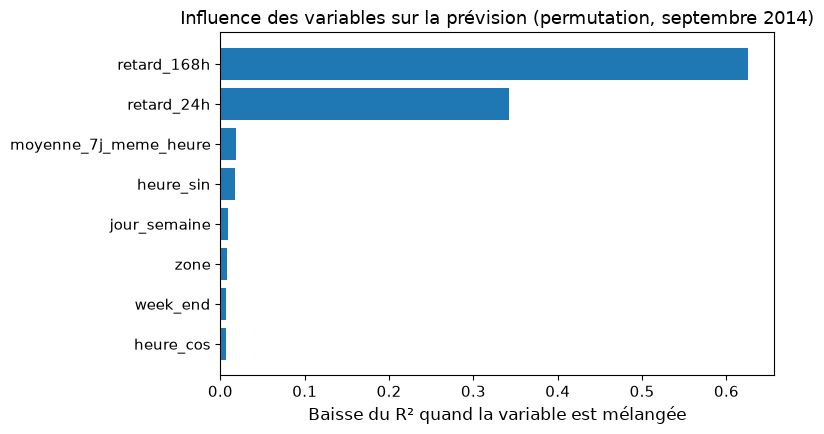

In [18]:
# =============================================================================
# 10 bis.6 — Influence des variables (C3.4) : importance par permutation
# =============================================================================
# Principe : on mélange au hasard UNE variable du jeu de test et l'on mesure la
# dégradation du R². Plus la chute est forte, plus le modèle s'appuie sur cette
# variable. La méthode vaut pour tout modèle, y compris le gradient boosting,
# qui n'a pas de coefficients lisibles.

# Le modèle retenu (section 10 bis.4) a la MAE de validation croisée la plus basse.
importance = permutation_importance(
    modele_retenu, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="r2"
)
tableau_importance = (
    pd.DataFrame(
        {
            "variable": VARIABLES,
            "baisse moyenne du R²": importance.importances_mean,
            "écart-type": importance.importances_std,
        }
    )
    .sort_values("baisse moyenne du R²", ascending=False)
    .reset_index(drop=True)
)
afficher(tableau_importance.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(tableau_importance["variable"], tableau_importance["baisse moyenne du R²"])
ax.invert_yaxis()
ax.set_title("Influence des variables sur la prévision (permutation, septembre 2014)")
ax.set_xlabel("Baisse du R² quand la variable est mélangée")
plt.tight_layout()
plt.show()

In [19]:
# =============================================================================
# 10 bis.7 — Recommandations tirées des prédictions
# =============================================================================
# Exemple opérationnel : prévision du vendredi 26 septembre 2014 à 18 h
# (dernier vendredi du jeu de test), zone par zone, comparée au réel.
creneau = jeu_test[jeu_test["heure_pleine"] == pd.Timestamp("2014-09-26 18:00:00")].copy()
creneau["prévu"] = modele_retenu.predict(creneau[VARIABLES]).round(0)
creneau["repère"] = creneau["zone"].map(noms_zones)
afficher(
    creneau[["zone", "repère", "pickups", "prévu"]]
    .rename(columns={"pickups": "réel"})
    .sort_values("prévu", ascending=False)
)

variable_principale = tableau_importance.loc[0, "variable"]
zone_principale = creneau.sort_values("prévu", ascending=False).iloc[0]["repère"]
print("RECOMMANDATIONS")
if gain > 0:
    print(
        f"1. Positionner les chauffeurs selon la prévision horaire par zone : elle réduit "
        f"l'erreur de {gain:.1f} courses par zone et par heure "
        f"({-100 * gain / mae_ref:.1f} %) par "
        f"rapport à la règle « comme la semaine précédente ». Le gain est {qualificatif} et "
        f"inégal selon les zones ({n_zones_gagnantes} zones sur {len(par_zone)} en profitent) : "
        "à confirmer par un test A/B avant généralisation."
    )
else:
    print("1. Conserver la règle « comme la semaine précédente » : le modèle ne l'améliore pas.")
print(
    f"2. La variable la plus influente est « {variable_principale} » : la demande d'une "
    "heure se prévoit d'abord par son historique récent. Le modèle doit donc être "
    "alimenté chaque jour avec les données de la veille."
)
print(
    f"3. Au créneau vendredi 18 h, la zone la plus demandée est « {zone_principale} » : "
    "y orienter les chauffeurs disponibles en priorité, puis suivre l'ordre du tableau."
)
print(
    f"4. Les pointes sont sous-estimées ({biais_pointes:+.1f} % sur les 5 % d'heures les plus "
    f"chargées) : prévoir une marge sur les heures de pointe et réentraîner souvent."
)
print(
    "5. Limite : ni la météo, ni les événements, ni l'offre de chauffeurs ne "
    "figurent dans les données. Un test A/B sur une zone pilote mesurerait le gain réel "
    "en temps d'attente."
)

,zone,repère,réel,prévu
4944,0,Midtown Manhattan / Times Square,1180,849.0
4946,2,Chelsea / Flatiron,983,828.0
4948,4,Upper East Side,381,301.0
4950,6,Downtown Brooklyn / DUMBO,292,245.0
4945,1,LaGuardia Airport,103,133.0
4947,3,JFK Airport,45,47.0
4951,7,South Bronx,26,36.0
4949,5,Newark / Jersey City,20,26.0


RECOMMANDATIONS
1. Positionner les chauffeurs selon la prévision horaire par zone : elle réduit l'erreur de 2.0 courses par zone et par heure (-5.6 %) par rapport à la règle « comme la semaine précédente ». Le gain est modeste et inégal selon les zones (6 zones sur 8 en profitent) : à confirmer par un test A/B avant généralisation.
2. La variable la plus influente est « retard_168h » : la demande d'une heure se prévoit d'abord par son historique récent. Le modèle doit donc être alimenté chaque jour avec les données de la veille.
3. Au créneau vendredi 18 h, la zone la plus demandée est « Midtown Manhattan / Times Square » : y orienter les chauffeurs disponibles en priorité, puis suivre l'ordre du tableau.
4. Les pointes sont sous-estimées (-17.9 % sur les 5 % d'heures les plus chargées) : prévoir une marge sur les heures de pointe et réentraîner souvent.
5. Limite : ni la météo, ni les événements, ni l'offre de chauffeurs ne figurent dans les données. Un test A/B sur une zone pilote me

## 11. Interprétation métier et limites

### Résultats principaux

- La demande est concentrée sur Manhattan, surtout Midtown / Chelsea / Flatiron.
- Les jours ouvrés ont un pic très net vers 17h–18h.
- Le week-end décale la zone dominante vers Chelsea / Flatiron et maintient des poches à Brooklyn et Upper East Side.
- Les aéroports représentent des clusters moins volumineux mais stratégiques pour le dispatching.
- La prévision supervisée (section 10 bis) apporte un gain **modeste** sur la règle « comme la semaine précédente » (voir les chiffres de la section 10 bis.5), concentré dans une zone, et sous-estime les pointes d'une demande en hausse.

### Limites assumées

- Le clustering apprend la demande historique, pas la disponibilité chauffeurs ni l'ETA réelle.
- KMeans impose des clusters convexes et peut lisser des frontières urbaines irrégulières.
- Les noms de quartiers sont approximatifs : le modèle sort des coordonnées, pas des noms administratifs ; au-delà de 3 km, le libellé le signale.
- La prévision suppose une tendance stable : septembre dépasse les niveaux d'apprentissage et les pointes sont sous-prévues.
- Le retard d'une semaine (`retard_168h`) est à la fois la règle de référence et la variable la plus influente par permutation sur septembre ; son utilité n'est pas établie hors de ce mois : un contrôle fait hors du notebook, en validation croisée sur avril à août, a donné un gradient boosting un peu meilleur sans cette variable, et elle porte en partie la hausse de septembre.
- La production devrait intégrer des données temps réel : météo, événements, trafic, offre chauffeurs et annulations.

### Critères de validation proposés en production

- baisse du temps d'attente moyen ;
- baisse du taux d'annulation après demande ;
- hausse du taux d'acceptation chauffeur ;
- comparaison A/B test contre la stratégie actuelle de positionnement.

In [20]:
# Sauvegarde des résultats principaux pour réutilisation dans un dashboard ou une API.
# lineterminator="\n" : fins de ligne LF sur tous les systèmes.
monthly_counts.to_csv(OUT / "monthly_counts.csv", index=False, lineterminator="\n")
weekday_counts.to_csv(OUT / "weekday_counts.csv", index=False, lineterminator="\n")
hourly_counts.to_csv(OUT / "hourly_counts.csv", index=False, lineterminator="\n")
daily_hotzones.to_csv(OUT / "daily_hotzones.csv", index=False, lineterminator="\n")
summary_pivot.reset_index().to_csv(
    OUT / "daily_hotzones_top3.csv", index=False, lineterminator="\n"
)
fri18_stats.to_csv(OUT / "friday_18_hotzones.csv", index=False, lineterminator="\n")

# Résultats de la prévision supervisée : validation croisée, test, erreurs par zone.
tableau_cv.to_csv(OUT / "forecast_cv.csv", index=False, lineterminator="\n")
tableau_resultats.to_csv(OUT / "forecast_test_metrics.csv", index=False, lineterminator="\n")
par_zone.to_csv(OUT / "forecast_by_zone.csv", index=False, lineterminator="\n")

summary = {
    "raw_rows": len(raw),
    "clean_rows": len(df),
    "removed_rows": len(raw) - len(df),
    "removed_pct": round(100 * (len(raw) - len(df)) / len(raw), 3),
    "date_min": str(raw["datetime"].min()),
    "date_max": str(raw["datetime"].max()),
    "top_weekday": weekday_counts.sort_values("pickups", ascending=False).iloc[0].to_dict(),
    "top_hour": hourly_counts.sort_values("pickups", ascending=False).iloc[0].to_dict(),
    "k_day": K_DAY,
    "k_hour": K_HOUR,
    "daily_quality_mean": daily_quality[["silhouette", "davies_bouldin", "calinski_harabasz"]]
    .mean()
    .to_dict(),
    "friday_18_quality": fri18_quality,
    "forecast": {
        "retained_model": retenu_nom,
        "cv_r2_mean": float(
            tableau_cv.loc[
                tableau_cv["modèle"] == retenu_nom, "R² validation (moyenne 5 plis)"
            ].iloc[0]
        ),
        "test_r2": float(meilleur["R² test"]),
        "test_mae": float(mae_best),
        "reference_mae": float(mae_ref),
        "test_wape_pct": float(meilleur["WAPE test (%)"]),
        "reference_wape_pct": float(reference["WAPE test (%)"]),
        "bias_peaks_pct": float(biais_pointes),
    },
}
with open(OUT / "summary.json", "w", encoding="utf-8", newline="\n") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

afficher(summary)

{'raw_rows': 4534327,
 'clean_rows': 4513100,
 'removed_rows': 21227,
 'removed_pct': 0.468,
 'date_min': '2014-04-01 00:00:00',
 'date_max': '2014-09-30 22:59:00',
 'top_weekday': {'weekday': 3, 'pickups': 752167, 'jour': 'Jeudi'},
 'top_hour': {'hour': 17, 'pickups': 334749},
 'k_day': 8,
 'k_hour': 6,
 'daily_quality_mean': {'silhouette': 0.43245657852717806,
  'davies_bouldin': 0.6832057372672071,
  'calinski_harabasz': 1516.7503645827803},
 'friday_18_quality': {'n_rows': 54533,
  'k': 6,
  'silhouette': 0.3660832345485687,
  'davies_bouldin': 0.6929470119174668,
  'calinski_harabasz': 1222.486168340798,
  'inertia': 315368.96875},
 'forecast': {'retained_model': 'Gradient boosting (HistGradientBoosting)',
  'cv_r2_mean': 0.9089032530184025,
  'test_r2': 0.907,
  'test_mae': 34.164,
  'reference_mae': 36.202,
  'test_wape_pct': 19.209,
  'reference_wape_pct': 20.354,
  'bias_peaks_pct': -17.949404240772974}}

## 11 bis. Conformité RGPD — des données de géolocalisation

Les données Uber 2014 sont publiques, mais **une localisation horodatée est une donnée personnelle
au sens du RGPD** dès qu'elle peut être rattachée à une personne : l'article 4.1 cite expressément
les « données de localisation » parmi les éléments qui rendent une personne identifiable. Un point
de départ répété chaque matin à la même heure désigne un domicile. Le projet applique donc les
principes de l'article 5 :

| Principe (RGPD, art. 5) | Application dans ce notebook |
|---|---|
| Minimisation | Seules quatre colonnes sont lues : date et heure, latitude, longitude, base. Aucun identifiant de client, de chauffeur ni de course |
| Limitation des finalités | Les données servent à estimer une demande **agrégée** par zone et par heure, jamais à suivre un individu |
| Agrégation | Les résultats exportés (`uber_outputs/`) sont des comptes par mois, jour et heure, des centroïdes de zones et des erreurs de prévision : aucune coordonnée individuelle n'est exportée |
| Exactitude | Les coordonnées hors de la zone de New York sont écartées (section 3) |
| Limitation de la conservation | En production : conserver les points bruts le temps du calcul, puis seulement les agrégats |
| Intégrité et confidentialité | Les fichiers bruts restent hors du dépôt public ; seuls le code et les agrégats y figurent |

**Risque résiduel** : les cartes des sections 5, 8 bis et 9
affichent des points individuels (en échantillon). Sur des données réelles et récentes, on ne publierait que des
densités agrégées (hexagones avec un nombre minimal de courses), pour empêcher la réidentification
d'un trajet isolé.

## 12. Conclusion

Le notebook répond au besoin initial en deux volets. **Où** : des hot-zones historiques actionnables, par jour de la semaine (sept cartes, section 8 bis) et pour un créneau (vendredi 18 h), obtenues par `MiniBatchKMeans` avec un nombre de zones justifié (sections 7 et 9) ; la sensibilité de DBSCAN à `eps` a été mesurée (section 9 ter). **Combien** : une prévision supervisée de la demande par zone et par heure (section 10 bis), validée dans le temps (septembre jamais vu, zonage ajusté sans lui) et comparée à la règle « comme la semaine précédente » : le gain est modeste, inégal selon les zones, et les pointes d'une demande en hausse sont sous-estimées. Ces limites sont chiffrées (WAPE et biais par zone) et non cachées.

La solution est simple à expliquer au métier, reproductible avec Scikit-Learn, et extensible. Prochaines étapes : ajouter météo, événements et offre de chauffeurs, réentraîner à fréquence rapprochée pour suivre la tendance, puis valider le gain réel par un test A/B (temps d'attente, taux d'annulation, taux d'acceptation).